---
title: "Higbie's penetration model: what a fixed contact time predicts, and the one measurement on disk that can test it"
description: "Replace the steady film by a surface element exposed for a fixed time and k_L becomes 2 sqrt(D / pi t_exp), with the contact time supplied by the hydrodynamics, not fitted. Read from Bird, Stewart & Lightfoot section 18.5; cross-checked against Froment, De Wilde & Bischoff section 6.4; and set against Whitman's film and Danckwerts' surface renewal on the one printed table that carries all three."
categories: [sec:A, struct:S4, tier:T0, data:tier6, phase:gas-liquid]
date: 2026-08-09
---

# Higbie's penetration model

**Catalog ID:** `A3.2` · **Structures:** `S4` (1-D transient diffusion,
marched in the flow direction) · **Tier:** T0

A liquid surface is exposed to a gas for a definite length of time, absorbs by
unsteady diffusion the whole while, and is then swept away and replaced. Nothing
reaches a steady state; there is no film thickness anywhere in the argument. The
mass-transfer coefficient that comes out is

$$k_L = 2\sqrt{\frac{\mathscr{D}_{AB}}{\pi\,t_{\rm exp}}},$$

so $k_L \propto \mathscr{D}^{1/2}$ where film theory gives $k_L \propto \mathscr{D}$.

**Where this page reads the model from, and where it does not.** R. Higbie,
*Trans. AIChE* **31**, 365-389 (1935) is the origin. It is pre-DOI, it is not on
disk, and **it was not consulted**. Everything below is read from
**Bird, Stewart & Lightfoot, *Transport Phenomena*, 2nd edn (Wiley, 2002),
section 18.5** (book pp. 558-561), which derives the result, names it the
"penetration model", attributes it to Higbie in the same paragraph, and prints
the full citation with a biographical footnote. A second book on disk,
**Froment, De Wilde & Bischoff, *Chemical Reactor Analysis and Design*, 3rd edn
(Wiley, 2011), section 6.4**, is used as a **cross-check only**: it treats
Higbie's picture as the uniform-surface-age special case of surface renewal and
prints the same constant and a closed-form enhancement factor, independently.
Where the two books disagree, that is reported as a finding, not adjudicated.

**What this page has that its two siblings do not.**
[`A3.1`](../A3.1-whitman-two-film/) (Whitman's two films) and
[`A3.3`](../A3.3-danckwerts-surface-renewal/) (Danckwerts' surface renewal)
cannot separate the three pictures from their own sources. This page takes the
comparison, with two things the others do not have: **one measured
mass-transfer coefficient** (Hammerton & Garner's 117 cm/hr for CO2 bubbles,
quoted in BSL's Problem 18A.7) and **one printed table carrying all three models
side by side** (Froment's Table 6.4.2.1). What those two can and cannot settle is
the subject of *Results*.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.01.3"  # replaced by the release tag at publication
PYMRM = ">=3.3.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "A3.2-higbie-penetration"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.integrate import quad
from scipy.optimize import brentq
from scipy.special import erf, erfc
from pymrm.checks import find_roots, observed_orders
from gallery_utils import load_data, load_meta, cite_data, Claims
from model import Film, phi_extrapolated, phi_penetration, phi_wall_series  # this page's model.py

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200, "display.max_columns", 20)
claims = Claims(PAGE.split("-")[0])
BREAK = []


def brk(row, metric, broken):
    """One injected defect: ``broken`` is what claim ``metric`` becomes with it."""
    caught = claims.breaks(row, metric, broken)
    BREAK.append((row, metric, claims[metric], float(broken), caught))
    return caught


def rel(a, b):
    return a / b - 1

## Background

Whitman's film (1923) explains a liquid-side resistance by putting a stagnant
layer of thickness $\delta$ against the interface and letting it reach steady
state: $k_L = \mathscr{D}/\delta$. Section 18.5 sets up a different picture, and
BSL states it as a restriction rather than as an objection: the diffusion is to
take place "so slowly in the liquid film that $A$ will not 'penetrate' very far
into the film, that is, that the penetration distance will be small in
comparison with the film thickness." In the two systems the section and its
worked Example are about (liquid running down a wetted wall, liquid sliding
round a rising bubble) **the contact is too short for a steady state to be
established at all**: the solute penetrates a short distance into a surface that
is moving past, and then that piece of surface is gone.

**Whose argument that is, exactly.** All BSL prints about the 1935 paper is one
sentence, "This approach for studying gas absorption was apparently first
proposed by Higbie", plus footnote 5, which is the citation and a biographical
note that also credits him with having "provided the basis for the 'penetration
model' of mass transfer". It does not say what Higbie's own argument was, which
geometries he treated, or what he compared his result against. The origin was not
consulted here, so **nothing on this page is attributed to the 1935 paper beyond
what BSL prints about it and, where Froment's cross-check is described, what
Froment prints about it**: his "Higbie's uniform age $\bar t$", printed
immediately above his Eq. 6.4.1-10, and his opening of section 6.4. Every
problem, example and contact time below is BSL's or Froment's, and is named as
such.

That changes what has to be solved. The film gives an ordinary differential
equation in one steady coordinate; penetration gives the transient diffusion
equation, with the time variable supplied by the flow. It also changes what is
*adjustable*. A film thickness is not observable and must be fitted. **A contact
time, in the two examples BSL applies the result to, is not fitted: it is
$L/v_{\max}$ for the falling film of section 18.5, and $D/v_t$ for the bubble of
diameter $D$ rising at $v_t$ in BSL's Example 18.5-1**, both set by the geometry
and the hydrodynamics. That is the difference this page is built around, because
it makes one of the three pictures falsifiable on a single measurement and the
other two not.

**Where the sibling pages leave the question.** `A3.1` establishes that Whitman's
three runs cannot see the diffusivity exponent. `A3.3` proves *why* its own
source cannot settle it: Danckwerts' one physical number, $s \approx 5\ {\rm
s^{-1}}$, is obtained by inverting $k_L=\sqrt{\mathscr{D}s}$, and film theory
fits the same single datum exactly as well by inverting $k_L=\mathscr{D}/\delta$:
**one free constant each, one datum, zero residual each**. That argument is
`A3.3`'s and is not re-derived here; what this page adds is a case in which the
penetration model has *no* free constant to absorb the datum with. Neither
sibling's CSV is loaded here: nothing in them is an input to anything below, and
their conclusions are referred to as theirs.

**A source that does not qualify.** Levenspiel's *Chemical Reaction Engineering*
(3rd edn, 1999) is on disk and mentions Higbie ("Alternatives to the film theory
are also in use. These models [Higbie (1935); Danckwerts (1950, 1955)] view that
the liquid at the interface is continually washed ..."), with the reference in the
chapter list. Named and attributed, but neither derived nor tested. It is not used
for this case.

## The published model

Everything in this section is transcribed from BSL section 18.5 on 300 ppi
renders of the scan at its native resolution. The equation numbers are BSL's.

**The problem.** Gas $A$ is absorbed by a laminar film of liquid $B$ running down
a wall, $A$ only slightly soluble so the velocity field is unaffected. The
velocity profile is Eq. 18.5-1,

$$v_z(x) = v_{\max}\left[1-\left(\frac{x}{\delta}\right)^{2}\right],$$

$x$ measured from the gas-liquid interface into the film of thickness $\delta$.
A shell balance and the two flux approximations (convection only in $z$,
diffusion only in $x$) give Eq. 18.5-7,

$$v_{\max}\left[1-\left(\frac{x}{\delta}\right)^{2}\right]\frac{\partial c_A}{\partial z}
  = \mathscr{D}_{AB}\frac{\partial^{2}c_A}{\partial x^{2}},$$

with B.C. 1 $c_A=0$ at $z=0$ (Eq. 18.5-8), B.C. 2 $c_A=c_{A0}$ at $x=0$
(Eq. 18.5-9), and B.C. 3 $\partial c_A/\partial x=0$ at $x=\delta$
(Eq. 18.5-10): $A$ cannot diffuse through the wall. BSL notes that this problem
"has been solved analytically in the form of an infinite series" (footnote 2:
R. L. Pigford, PhD thesis, University of Illinois, 1941) **but does not give that
solution**.

**The penetration approximation.** Instead BSL argues that if $A$ has penetrated
only a short distance, it "has the impression" that the film moves everywhere at
$v_{\max}$, and it does not "sense" the wall, so Eq. 18.5-7 and its boundary
conditions are replaced by Eq. 18.5-11,

$$v_{\max}\frac{\partial c_A}{\partial z} = \mathscr{D}_{AB}\frac{\partial^{2}c_A}{\partial x^{2}},$$

with $c_A=0$ at $z=0$, $c_A=c_{A0}$ at $x=0$, and $c_A=0$ at $x=\infty$
(Eqs. 18.5-12 to 14). **Two approximations are made at once here, and *Results 7*
separates them.** The solution is Eq. 18.5-16,

$$\frac{c_A}{c_{A0}} = \operatorname{erfc}\frac{x}{\sqrt{4\mathscr{D}_{AB}z/v_{\max}}},$$

the interfacial flux is Eq. 18.5-17,

$$N_{Ax}\big\vert_{x=0} = c_{A0}\sqrt{\frac{\mathscr{D}_{AB}v_{\max}}{\pi z}},$$

and the total absorbed by a film of length $L$ and width $W$ is Eq. 18.5-18,

$$W_A = WLc_{A0}\sqrt{\frac{4\mathscr{D}_{AB}v_{\max}}{\pi L}}.$$

BSL adds that "the same result is obtained by integrating the product
$v_{\max}c_A$ over the flow cross section at $z=L$ (see Problem 18C.3)": a mass
balance rather than a surface-flux integral, and the route the numerical solve
below uses.

**The attribution, and the exposure time.** Immediately after Eq. 18.5-18:
"Equation 18.5-18 shows that the mass transfer rate is directly proportional to
the square root of the diffusivity and inversely proportional to the square root
of the 'exposure time,' $t_{\rm exp}=L/v_{\max}$. This approach for studying gas
absorption was apparently first proposed by Higbie.$^5$ The problem discussed in
this section illustrates the 'penetration model' of mass transfer. This model is
discussed further in Chapters 20 and 22." Footnote 5 is the full Higbie citation.
Writing Eq. 18.5-18 as $W_A = WL\,k_L c_{A0}$ gives the coefficient quoted at the
top of this page.

**The bubble, and the one place a measurement enters.** Example 18.5-1 applies the
same result to a gas bubble with internal (Rybczynski-Hadamard) circulation by
replacing $t_{\rm exp}=L/v_{\max}$ with $D/v_t$, $D$ the bubble diameter, giving
Eq. 18.5-19,

$$(N_A)_{\rm avg} = \sqrt{\frac{4\mathscr{D}_{AB}v_t}{\pi D}}\;c_{A0}.$$

BSL: this "turns out to be correct for potential flow of the liquid around the
bubble ... This equation has been approximately confirmed$^6$ for gas bubbles 0.3
to 0.5 cm in diameter rising through carefully purified water", footnote 6 being
D. Hammerton and F. H. Garner, *Trans. Inst. Chem. Engrs. (London)* **32**,
S18-S24 (1954). For **creeping** flow the corresponding result is Eq. 18.5-20,

$$(N_A)_{\rm avg} = \sqrt{\frac{4\mathscr{D}_{AB}v_t}{3\pi D}}\;c_{A0},$$

attributed to Levich, lower than Eq. 18.5-19 by exactly $\sqrt3$. BSL also records
that a surfactant skin, by killing the internal circulation, drops the exponent to
$\mathscr{D}^{1/3}$ "as for a solid sphere", and section 18.6 (a solid dissolving
into a falling film, where the velocity gradient at the interface is finite rather
than zero) gives $\mathscr{D}^{2/3}$. **Four exponents, then, in one chapter:**
$\mathscr{D}^{1}$ (film), $\mathscr{D}^{1/2}$ (penetration, mobile interface),
$\mathscr{D}^{2/3}$ (linear velocity gradient) and $\mathscr{D}^{1/3}$ (rigid
sphere).

**The cross-check.** Froment, De Wilde & Bischoff section 6.4 arrives at the same
constant from the other direction. Treating Higbie's uniform surface age $\bar t$
as a special case of the surface-age distribution, their Eq. 6.4.1-10 is followed
by: "since, for purely physical absorption, $N_A = 2C_{Ai}\sqrt{D_A/\pi\bar t}$,
but also $N_A = k_L C_{Ai}$." That is BSL's coefficient, from a different book,
a different derivation and a different starting point. They also print, as their
Eq. 6.4.2-8, the enhancement factor Higbie's uniform age gives for a
pseudo-first-order reaction,

$$F_A = \gamma\left[\left(1+\frac{\pi}{8\gamma^{2}}\right)
        \operatorname{erf}\!\left(\frac{2}{\sqrt\pi}\gamma\right)
        + \frac{1}{2\gamma}\exp\!\left(-\frac{4}{\pi}\gamma^{2}\right)\right],
  \qquad \gamma^{2}=\frac{D_Ak}{k_L^{2}},$$

against $\sqrt{1+\gamma^2}$ for Danckwerts' surface renewal (their Eq. 6.4.2-7)
and $\gamma/\tanh\gamma$ for the film. Their Table 6.4.2.1 tabulates all three.

## Parameters and assumptions

**Nothing on this page uses a transport property that is not printed in a source
on disk.** The two worked problems supply their own diffusivities, solubilities
and velocities; the one molecular weight needed comes from BSL's own Table E.1.

- **`18A.4`, chlorine into a falling water film.** $R=1.4$ cm and $L=13$ cm are
  text labels on Fig. 18A.4 (nothing is traced or digitised); $\langle v\rangle
  =17.7$ cm/s, $\mathscr{D}_{AB}=1.26\times10^{-5}$ cm$^2$/s and a saturation of
  0.823 g Cl$_2$ per 100 g water at 16 C are printed in the statement. The wetted
  width is $W=2\pi R$.
- **The factor $3/2$ is derived, not remembered.** Eq. 18.5-18 is written in
  $v_{\max}$ and the problem prints $\langle v\rangle$. Averaging the *printed*
  Eq. 18.5-1 across the film,
  $\langle v_z\rangle = \frac{1}{\delta}\int_0^{\delta}v_{\max}[1-(x/\delta)^2]\,dx
  = \tfrac23 v_{\max}$, so $v_{\max} = \tfrac32\langle v\rangle$.
- **One assumption, flagged.** Converting "0.823 g per 100 g water" to
  mol cm$^{-3}$ needs the density of water, which the problem does not print. It
  is taken as exactly 1.000 g/cm$^3$ and the solution treated as dilute. *Results
  1* re-evaluates the answer at 0.999: the two densities fall on **opposite
  sides** of a three-figure rounding step, so the choice is not harmless, and the
  printed answer still cannot **decide between them**, because the rounding of an
  input 18A.4 *does* print (the diffusivity) moves the answer by more.
- **`18A.7`, CO$_2$ from a rising bubble.** $D=0.5$ cm, $v_t=22$ cm/s,
  $\mathscr{D}_{AB}=1.46\times10^{-5}$ cm$^2$/s and $c_{A0}=0.041$ g-mol/liter at
  18 C, 1 atm, all printed; and Hammerton & Garner's measured surface-averaged
  $k_c=117$ cm/hr, quoted by BSL from a paper that is **not on disk and was not
  consulted**.
- **$\delta$ is never invented.** Problem 18A.4 prints no film thickness, no
  viscosity and no flow rate, so the finite-thickness correction is reported as a
  threshold in the dimensionless group $\Lambda = \mathscr{D}_{AB}L/(v_{\max}
  \delta^{2})$ and as the $\delta$ at which that correction reaches 1 %, rather
  than as a number for that column.
- **Nothing on this page is stochastic.**

## The data

Three CSVs, all of them printed numbers rather than measurements, which is why
the data tier is **6**. Two come from the pinned source (BSL), one from the
cross-check (Froment).

1. `bsl-2002-sec18p5-worked-problems.csv`: the inputs and printed answers of
   Problems 18A.4 and 18A.7, plus the molecular weight of Cl$_2$ from BSL's
   Table E.1. One row, `bub_kc_measured`, is a **measurement**: Hammerton &
   Garner's 117 cm/hr, quoted by BSL. That paper is not on disk and was not
   consulted; BSL prints no error bar for it and none is invented.
2. `bsl-2002-penetration-vs-film-tables.csv`: BSL's Table 20.1-1 (Arnold's
   $\varphi$ and $\psi$) and Table 22.8-2, headed *Comparison of Film and
   Penetration Models*. **That table is not about the exponent on diffusivity**;
   it compares the two models' corrections $\theta_x$ for a finite net
   mass-transfer rate. The Arnold problem itself is case `A4.8`; $\varphi$ and
   $\psi$ appear here only because Eq. 22.8-41 needs them.
3. `froment-2011-table6p4p2-1-three-models.csv`: Froment's Table 6.4.2.1,
   film, surface renewal and penetration enhancement factors at six $\gamma$.
   Froment prints it "After Beek [1968]"; **Beek 1968 is not on disk and was not
   consulted**, so every statement made about these numbers is a statement about
   Froment's printing.

The two tables are also read as strings, so that each cell's rounding window
comes from the digits it is printed with (`0.270` read as a float would lose a
digit). **No other page's dataset is loaded.**

In [3]:
prob = load_data("bsl-2002-sec18p5-worked-problems.csv", page=PAGE).set_index("id")
tabs = load_data("bsl-2002-penetration-vs-film-tables.csv", page=PAGE)
tabs_str = load_data("bsl-2002-penetration-vs-film-tables.csv", page=PAGE, dtype=str)
fro = load_data("froment-2011-table6p4p2-1-three-models.csv", page=PAGE)
fro_str = load_data("froment-2011-table6p4p2-1-three-models.csv", page=PAGE, dtype=str)

for _name in ("bsl-2002-sec18p5-worked-problems.csv",
              "froment-2011-table6p4p2-1-three-models.csv"):
    print(cite_data(load_meta(_name, page=PAGE)).replace(f" {chr(0x2014)} ", ", "))


def P(key):
    """A value BSL prints, by its row id in the worked-problems CSV."""
    return float(prob.loc[key, "value"])


def half_unit(cells):
    """Half a unit in the last printed place of each cell, from its string."""
    return np.array([0.5 * 10.0 ** -len(str(c).partition(".")[2]) for c in cells])


display(prob[["problem", "quantity", "value", "unit", "role"]])
display(tabs)
display(fro)

Bird, R. B.; Stewart, W. E.; Lightfoot, E. N. (2002), Transport Phenomena, 2nd edition, John Wiley & Sons, table
Froment, G. F.; De Wilde, J.; Bischoff, K. B. (2011), Chemical Reactor Analysis and Design, 3rd edition, John Wiley & Sons, ISBN 978-0-470-56541-4, table


,problem,quantity,value,unit,role
id,,,,,
film_R,18A.4,inside radius of the wetted-wall column,1.400000,cm,input
film_L,18A.4,wetted length of the column,13.000000,cm,input
film_v_avg,18A.4,average velocity of the water film,17.700000,cm/s,input
film_D,18A.4,liquid-phase diffusivity of the chlorine-water...,0.000013,cm2/s,input
film_solubility,18A.4,saturation concentration of chlorine in water,0.823000,g Cl2 per 100 g water,input
film_T,18A.4,temperature,16.000000,degC,input
film_WA_printed,18A.4,absorption rate,0.273000,g-mol/hr,printed_answer
bub_D_bubble,18A.7,bubble diameter,0.500000,cm,input
bub_DAB,18A.7,liquid-phase diffusivity of CO2 in water,0.000015,cm2/s,input


,x_A0,phi_20p1_1,psi_20p1_1,theta_penetration_22p8_2,theta_film_22p8_2
0,0.00,0.0000,1.000,1.000,1.000
1,0.25,0.1562,1.108,0.831,0.863
2,0.50,0.3578,1.268,0.634,0.693
3,0.75,0.6618,1.564,0.391,0.462
4,1.00,NaN,NaN,0.000,0.000


,gamma,FA_film_printed,FA_surface_renewal_printed,FA_penetration_printed
0,0.01,1.00,1.00,0.940
1,0.10,1.00,1.00,1.005
2,0.30,1.04,1.04,1.035
3,1.00,1.31,1.41,1.370
4,3.00,3.02,3.16,3.120
5,10.00,10.00,10.05,10.390


### What the sources say about these rows, and what it costs

- BSL prints Problem 18A.7's answers to **three** significant figures and
  18A.4's to three as well. Every reproduction below is therefore at best a
  0.2 %-level statement, and 18A.4's residual is *at* that level, not under it.
- Section 18.5 itself carries **no numerical result**. The only figures printed
  anywhere in it are the "0.3 to 0.5 cm" bubble-diameter range over which BSL
  says Eq. 18.5-19 was approximately confirmed, and the $\mathscr{D}^{1/3}$
  exponent of a surfactant-skinned bubble, which book p. 561 contrasts with the
  $\mathscr{D}^{1/2}$ of Eq. 18.5-19. (The $\mathscr{D}^{2/3}$ belongs to
  **section 18.6**, not to 18.5: book p. 563 is where BSL writes "in §18.5,
  $W_A\propto(\mathscr{D}_{AB}L)^{1/2}$, whereas in this section
  $W_A\propto(\mathscr{D}_{AB}L)^{2/3}$".) Everything else is derivation and
  attribution; the numbers live in the problems.
- The 117 cm/hr is a *surface-averaged* coefficient over a rising bubble, and
  BSL's own words for the agreement are "approximately confirmed". The page does
  not upgrade that to a validation.
- **Table 22.8-2's penetration column is not an independent computation.** It is
  Table 20.1-1's $\psi$ column multiplied by $(1-x_{A0})$, which is exactly what
  Eq. 22.8-41 says. The two reproductions below therefore carry the same
  information, and the notebook prints that coincidence instead of presenting
  them as two checks.
- Froment's Table 6.4.2.1 rows at $\gamma=0.01$ and $\gamma=10$ are examined
  below; they are inconsistent with the closed form printed at the head of their
  own column, and they are reported, not corrected.

## PyMRM implementation

The structure is `S4`: a one-dimensional transient diffusion problem, here
*marched* in the axial distance $z$, which plays the role of time because
Eq. 18.5-7 has no axial diffusion. Non-dimensionalise with $\xi=x/\delta$,
$\zeta=z/L$, $u=c_A/c_{A0}$ and

$$\Lambda \equiv \frac{\mathscr{D}_{AB}L}{v_{\max}\delta^{2}},
\qquad\text{so}\qquad
(1-\xi^{2})\frac{\partial u}{\partial\zeta} = \Lambda\frac{\partial^{2}u}{\partial\xi^{2}},$$

with $u(\xi,0)=0$, $u(0,\zeta)=1$ and $\partial u/\partial\xi\vert_{\xi=1}=0$. The
penetration depth relative to the film is $\sqrt{4\Lambda}$, so $\Lambda\to0$ is
BSL's short-contact-time limit. One class, `Film` in `model.py`, covers every case
the page needs by switching two things independently:

- the **capacity** $(1-\xi^{2})$, the parabolic velocity profile, or $1$ for plug
  flow at $v_{\max}$ (`profile=`): BSL's first approximation;
- the **outer boundary**, a no-flux wall at $\xi=1$ or a domain several
  penetration depths deep (`XI=`): BSL's second approximation.

Turning both off gives Eq. 18.5-11; turning both on gives Eq. 18.5-7. The
dimensionless uptake reported at the outlet is the mixing cup

$$\Phi \equiv \int_{0}^{1}(1-\xi^{2})\,u(\xi,1)\,d\xi
  \qquad\Longrightarrow\qquad W_A = W\,\delta\,v_{\max}c_{A0}\,\Phi,$$

which is BSL's Problem 18C.3 route. In the penetration limit
$\Phi\to\sqrt{4\Lambda/\pi}$ and $\delta$ cancels out of $W_A$, as it must.

**What is pymrm and what is not.** The transverse operator
$\Lambda\,\partial^2/\partial\xi^2$ and its boundary vector come from
`construct_grad` and `construct_div` on a grid stretched toward the interface,
assembled once in the constructor with the state shaped `(n_x, 1)`. The
interfacial flux is read with `compute_boundary_values` (gradient along $+\xi$,
so the flux into the film is $-\Lambda\,\partial u/\partial\xi$). The boundary
conditions use the **outward** normal and each carries its physical equation in a
comment. The march itself is numpy and scipy: backward Euler on steps uniform in
$\sqrt\zeta$, each step one
`scipy.linalg.solve_banded` call on the tridiagonal operator, which is stored once
in banded form, so a step only adds $\mathrm{cap}/\Delta\zeta$ to its diagonal.
Backward Euler is first order, so every production $\Phi$ is the Richardson
combination $2\Phi(2n_t)-\Phi(n_t)$ (`phi_extrapolated`), with the raw value kept
beside it. *Validation 3* measures that choice against BDF2 and Crank-Nicolson.
The cell below checks the banded solve against a sparse LU of the same step
matrix, assembled with `construct_coefficient_matrix` for the capacity.

In [4]:
_f = Film(0.1)
print(f"Film(0.1): n_x = {_f.n_x}, state shape {_f.shape}, cells from "
      f"{_f.dx[0]:.2e} at the interface to {_f.dx[-1]:.2e} at the wall")
print("boundary conditions, outward normal:")
for _side, _bc in zip(("xi = 0 ", "xi = XI"), _f.bc):
    print(f"   {_side}: a = {_bc['a']:g}, b = {_bc['b']:g}, d = {_bc['d']:g}")

from scipy.sparse.linalg import splu
from pymrm import construct_coefficient_matrix


def march_splu(film, n_t, refactor=True):
    """The same backward-Euler march with a sparse LU of the step matrix.

    The capacity enters as ``construct_coefficient_matrix``; with
    ``refactor=False`` the LU of the first step is reused for every step."""
    cap_mat = construct_coefficient_matrix(film.cap.reshape(film.shape), shape=film.shape)
    z = np.linspace(0.0, 1.0, n_t + 1) ** 2
    u, lu = np.zeros(film.n_x), None
    for dz in np.diff(z):
        if refactor or lu is None:
            lu = splu((cap_mat / dz - film.jac_diff).tocsc())
        u = lu.solve(film.cap * u / dz + film.g_const)
    return film.cup(u)


SPLU_GAP = abs(march_splu(_f, 800) / _f.march(800)["cup"] - 1)
print(f"\n800 steps on 600 cells: the banded solve and a sparse LU of the step matrix "
      f"give the same cup to below 1e-12 (here {SPLU_GAP:.1e})")
claims.bound("banded_vs_splu_cup_gap", SPLU_GAP, max=1e-12, basis="identity",
             note="the same linear equations, two direct solvers")

Film(0.1): n_x = 600, state shape (600, 1), cells from 2.50e-05 at the interface to 9.97e-03 at the wall
boundary conditions, outward normal:
   xi = 0 : a = 0, b = 1, d = 1
   xi = XI: a = 1, b = 0, d = 0



800 steps on 600 cells: the banded solve and a sparse LU of the step matrix give the same cup to below 1e-12 (here 1.0e-14)


## Results

### 1. Problem 18A.4, two ways

The closed form is Eq. 18.5-18. The second route never touches an error
function: it marches Eq. 18.5-11 on finite volumes and reads the outlet mixing
cup, which is BSL's Problem 18C.3 identity used as a *different* route to the
same number rather than as a check on itself.

In [5]:
R, L = P("film_R"), P("film_L")
v_avg, D_cl = P("film_v_avg"), P("film_D")
sol_g, M_Cl2 = P("film_solubility"), P("M_Cl2")
RHO_W = 1.000        # g/cm3, ASSUMED (not printed in the problem)
WA_printed = P("film_WA_printed")

W_wet = 2 * np.pi * R                       # wetted width of the column
v_max = 1.5 * v_avg                         # <v> = (2/3) v_max, from Eq. 18.5-1


def WA_hr(vmax=v_max, four=4.0, rho=RHO_W, mw=M_Cl2, D=D_cl, d_exp=0.5):
    """Eq. 18.5-18 in g-mol/hr; the arguments are the inputs a defect can change."""
    c = (sol_g / mw) / (100.0 / rho)                       # g-mol/cm3
    return (W_wet * L * c * np.sqrt(four / np.pi * vmax / L) * D ** d_exp * 3600.0)


cA0_cl = (sol_g / M_Cl2) / (100.0 / RHO_W)
t_exp_film = L / v_max
pen_depth_film = np.sqrt(4 * D_cl * t_exp_film)     # sqrt(4 D t_exp), cm
kL_film = 2 * np.sqrt(D_cl / (np.pi * t_exp_film))
WA_closed_hr = WA_hr()

# Second route: pymrm march of Eq. 18.5-11 (plug flow, deep domain). Lam is a free
# choice because delta cancels out of W_A in this limit; XI = 10 sqrt(4 Lam) puts
# the far boundary ten penetration depths away.
LAM_REF, NX_REF, NT_REF = 0.25, 600, 800
XI_REF = 10 * np.sqrt(4 * LAM_REF)
REF_FILM = dict(XI=XI_REF, n_x=NX_REF, stretch=4.0, profile="plug")
Phi_pymrm = phi_extrapolated(LAM_REF, NT_REF, **REF_FILM)["extrapolated"]


def ref_grid_ratio(which="extrapolated"):
    """How much the march's error against sqrt(4 Lam/pi) falls when n_x doubles."""
    e = [rel(phi_extrapolated(LAM_REF, NT_REF, **{**REF_FILM, "n_x": n})[which],
             phi_penetration(LAM_REF)) for n in (NX_REF, 2 * NX_REF)]
    return e[0] / e[1]


REF_RATIO = ref_grid_ratio()


def WA_pymrm_hr(phi=Phi_pymrm, vmax=v_max, rho=RHO_W, mw=M_Cl2):
    """W_A from the marched Phi, W delta v_max c_A0 Phi, with delta = sqrt(D L/(v_max Lam))."""
    c = (sol_g / mw) / (100.0 / rho)
    delta_ref = np.sqrt(D_cl * L / (vmax * LAM_REF))
    return W_wet * delta_ref * vmax * c * phi * 3600.0


WA_pymrm = WA_pymrm_hr()
claims.value("eq18518_vs_printed_18A4_rel", rel(WA_closed_hr, WA_printed))
claims.value("pymrm_vs_printed_18A4_rel", rel(WA_pymrm, WA_printed))
claims.value("pymrm_vs_eq18518_rel", rel(WA_pymrm, WA_closed_hr))
claims.value("wa_closed_gmol_per_hr", WA_closed_hr)
claims.bound("pymrm_vs_eq18518_grid_ratio", REF_RATIO, min=3.5, max=4.5, basis="theory",
             note="error of the march falls 4x when n_x doubles: a second-order grid error")

# Does the closed form round to the printed three figures? Three printed decimals
# allow +/- 0.0005, and the page must not claim more agreement than that.
WA_round3 = round(WA_closed_hr, 3)
round_half_rel = 0.0005 / WA_printed
RHO_ALT, MW_ALT = 0.999, 71.0      # two plausible unprinted alternatives
WA_rho999, WA_mw71 = WA_hr(rho=RHO_ALT), WA_hr(mw=MW_ALT)
D_half = 0.5 * 10.0 ** (np.floor(np.log10(D_cl)) - 2)   # D is printed to 3 figures


def D_window(d_exp=0.5):
    """How far half a unit in the last printed place of D moves W_A."""
    return max(abs(rel(WA_hr(D=D_cl + s * D_half, d_exp=d_exp), WA_hr(d_exp=d_exp)))
               for s in (1, -1))


D_window_rel = D_window()
WA_excess = WA_closed_hr - (WA_printed + 0.0005)        # how far outside the window
claims.value("rounding_window_rel", round_half_rel)
claims.value("wa_rho999_gmol_per_hr", WA_rho999)
claims.value("wa_mw71_gmol_per_hr", WA_mw71)
claims.value("D_half_unit_window_rel", D_window_rel)
claims.value("wa_excess_over_window_gmol_per_hr", WA_excess)
claims.value("film_exposure_time_s", t_exp_film)
claims.value("film_penetration_depth_um", pen_depth_film * 1e4)
claims.value("film_kL_cm_s", kL_film)

display(Markdown(rf"""
| route | absorption rate (g-mol/hr) | vs BSL's printed answer |
|---|---|---|
| Eq. 18.5-18, closed form | {WA_closed_hr:.5f} | {claims["eq18518_vs_printed_18A4_rel"]*100:+.3f} % |
| pymrm march of Eq. 18.5-11, outlet mixing cup | {WA_pymrm:.5f} | {claims["pymrm_vs_printed_18A4_rel"]*100:+.3f} % |
| **BSL, printed** | **{WA_printed:.3f}** | |

One route evaluates a square root; the other solves {NX_REF} cells over
{NT_REF} and {2*NT_REF} marching steps, extrapolates in the step and integrates
the outlet profile. They agree to {abs(claims["pymrm_vs_eq18518_rel"])*100:.1e} %,
which is the grid error of the march: on {2*NX_REF} cells it is
{REF_RATIO:.2f} times smaller. Both sit
{claims["eq18518_vs_printed_18A4_rel"]*100:+.2f} % from the printed answer.

**That residual is a hair *outside* three-figure rounding, not inside it.**
{WA_closed_hr:.5f} rounds to **{WA_round3:.3f}**, whereas BSL prints
**{WA_printed:.3f}**; three printed decimals allow $\pm${round_half_rel*100:.3f} %
and the deviation is {claims["eq18518_vs_printed_18A4_rel"]*100:+.3f} %. Two
inputs Problem 18A.4 does **not** print are each worth about that much. Taking the
density of water as {RHO_ALT} g/cm$^3$ instead of the assumed {RHO_W:.3f} gives
{WA_rho999:.5f} ({rel(WA_rho999, WA_printed)*100:+.3f} %); taking $M$(Cl$_2$) as
{MW_ALT} instead of Table E.1's {M_Cl2:.3f} gives {WA_mw71:.5f}
({rel(WA_mw71, WA_printed)*100:+.3f} %); **each of those rounds to the printed
{WA_printed:.3f}**.

**The excess is thin, and not theirs alone.** The amount to be explained is only
{WA_excess:.2e} g-mol/hr, {WA_excess/WA_closed_hr*100:.4f} % of the value, and the
inputs 18A.4 *does* print are three-figure as well. Half a unit in the last printed
place of $\mathscr{{D}}_{{AB}}$ moves $W_A$ by $\pm${D_window_rel*100:.3f} % on its
own, more than the whole $\pm${round_half_rel*100:.3f} % window; and if BSL
truncated to three decimals rather than rounding, {WA_closed_hr:.5f} sits inside
[{WA_printed:.3f}, {WA_printed+0.001:.3f}) and there is nothing to explain at all.
So the page does not conclude that BSL used either unprinted value: a three-figure
printed answer cannot tell, which is why neither is adopted.

**Which half of the calculation each number tests.** The two routes are *not*
independent end to end. The wetted width $W=2\pi R$, the factor $\tfrac32$, the
solubility conversion and the 3600 are computed once and enter both; and the
reference thickness $\delta_{{\rm ref}}=\sqrt{{\mathscr{{D}}L/(v_{{\max}}\Lambda)}}$
carries the same dimensional group back out of the march, so $W$, $c_{{A0}}$,
$v_{{\max}}$, $\mathscr{{D}}$, $L$ and the 3600 cancel identically out of the ratio.
`pymrm_vs_eq18518_rel` therefore **cannot see any of them**: the break table
injects $v_{{\max}}=\langle v\rangle$, $\rho$ = {RHO_ALT} and $M$(Cl$_2$) = {MW_ALT} into it
and it does not move. What it *does* test is the dimensionless solve, the marched
$\Phi(\Lambda)$ against $\sqrt{{4\Lambda/\pi}}$, an error function against
{NX_REF} finite volumes, with the 4 and the $\pi$ in it: drop the 4 from
Eq. 18.5-18 and it moves. **The dimensional prefactor is tested by the other
column of the table**: the {claims["eq18518_vs_printed_18A4_rel"]*100:+.3f} %
against BSL's printed {WA_printed:.3f} g-mol/hr is what says $W$, the $\tfrac32$,
the solubility conversion and the units are right, and it is the only thing on the
page that says so.

Exposure time $t_{{\rm exp}} = L/v_{{\max}}$ = **{t_exp_film:.4f} s**, penetration
depth $\sqrt{{4\mathscr{{D}}t_{{\rm exp}}}}$ = **{pen_depth_film*1e4:.1f} um**,
$k_L = 2\sqrt{{\mathscr{{D}}/\pi t_{{\rm exp}}}}$ = **{kL_film:.4e} cm/s**.
"""))


| route | absorption rate (g-mol/hr) | vs BSL's printed answer |
|---|---|---|
| Eq. 18.5-18, closed form | 0.27351 | +0.188 % |
| pymrm march of Eq. 18.5-11, outlet mixing cup | 0.27351 | +0.187 % |
| **BSL, printed** | **0.273** | |

One route evaluates a square root; the other solves 600 cells over
800 and 1600 marching steps, extrapolates in the step and integrates
the outlet profile. They agree to 4.6e-04 %,
which is the grid error of the march: on 1200 cells it is
3.92 times smaller. Both sit
+0.19 % from the printed answer.

**That residual is a hair *outside* three-figure rounding, not inside it.**
0.27351 rounds to **0.274**, whereas BSL prints
**0.273**; three printed decimals allow $\pm$0.183 %
and the deviation is +0.188 %. Two
inputs Problem 18A.4 does **not** print are each worth about that much. Taking the
density of water as 0.999 g/cm$^3$ instead of the assumed 1.000 gives
0.27324 (+0.088 %); taking $M$(Cl$_2$) as
71.0 instead of Table E.1's 70.905 gives 0.27315
(+0.054 %); **each of those rounds to the printed
0.273**.

**The excess is thin, and not theirs alone.** The amount to be explained is only
1.28e-05 g-mol/hr, 0.0047 % of the value, and the
inputs 18A.4 *does* print are three-figure as well. Half a unit in the last printed
place of $\mathscr{D}_{AB}$ moves $W_A$ by $\pm$0.199 % on its
own, more than the whole $\pm$0.183 % window; and if BSL
truncated to three decimals rather than rounding, 0.27351 sits inside
[0.273, 0.274) and there is nothing to explain at all.
So the page does not conclude that BSL used either unprinted value: a three-figure
printed answer cannot tell, which is why neither is adopted.

**Which half of the calculation each number tests.** The two routes are *not*
independent end to end. The wetted width $W=2\pi R$, the factor $\tfrac32$, the
solubility conversion and the 3600 are computed once and enter both; and the
reference thickness $\delta_{\rm ref}=\sqrt{\mathscr{D}L/(v_{\max}\Lambda)}$
carries the same dimensional group back out of the march, so $W$, $c_{A0}$,
$v_{\max}$, $\mathscr{D}$, $L$ and the 3600 cancel identically out of the ratio.
`pymrm_vs_eq18518_rel` therefore **cannot see any of them**: the break table
injects $v_{\max}=\langle v\rangle$, $\rho$ = 0.999 and $M$(Cl$_2$) = 71.0 into it
and it does not move. What it *does* test is the dimensionless solve, the marched
$\Phi(\Lambda)$ against $\sqrt{4\Lambda/\pi}$, an error function against
600 finite volumes, with the 4 and the $\pi$ in it: drop the 4 from
Eq. 18.5-18 and it moves. **The dimensional prefactor is tested by the other
column of the table**: the +0.188 %
against BSL's printed 0.273 g-mol/hr is what says $W$, the $\tfrac32$,
the solubility conversion and the units are right, and it is the only thing on the
page that says so.

Exposure time $t_{\rm exp} = L/v_{\max}$ = **0.4896 s**, penetration
depth $\sqrt{4\mathscr{D}t_{\rm exp}}$ = **49.7 um**,
$k_L = 2\sqrt{\mathscr{D}/\pi t_{\rm exp}}$ = **5.7240e-03 cm/s**.


### 2. Problem 18A.7(a): the instruction and the answer do not match

Part (a) says, in as many words, "Use Eq. 18.5-20": the **creeping-flow** result
with $3\pi D$ in the denominator. Evaluating both printed equations on the
problem's own printed inputs settles which one produced the printed answer.

In [6]:
D_bub, DAB, cA0_bub, vt = (P("bub_D_bubble"), P("bub_DAB"),
                           P("bub_cA0") * 1e-3, P("bub_vt"))   # liter -> cm3
Na_a, Na_b = P("bub_Na_printed_a"), P("bub_Na_printed_b")
kc_meas = P("bub_kc_measured") / 3600.0                        # cm/hr -> cm/s


def kL_bubble(texp, three=1.0):
    """2 sqrt(D/(pi t_exp)), Eq. 18.5-19 (three = 1) or Eq. 18.5-20 (three = 3)."""
    return 2 * np.sqrt(DAB / (three * np.pi * texp))


t_exp_bub = D_bub / vt
kL_19, kL_20 = kL_bubble(t_exp_bub), kL_bubble(t_exp_bub, three=3.0)
N19, N20, Nmeas = kL_19 * cA0_bub, kL_20 * cA0_bub, kc_meas * cA0_bub

claims.value("eq18519_vs_printed_18A7a_rel", rel(N19, Na_a))
claims.value("eq18520_vs_printed_18A7a_rel", rel(N20, Na_a))
claims.bound("eq18519_over_eq18520", kL_19 / kL_20, min=np.sqrt(3) - 1e-12,
             max=np.sqrt(3) + 1e-12, basis="identity", note="the two equations differ by sqrt(3)")
claims.value("hg_measured_vs_printed_18A7b_rel", rel(Nmeas, Na_b))

display(Markdown(rf"""
| equation | $(N_A)_{{\rm avg}}$ (g-mol cm$^{{-2}}$ s$^{{-1}}$) | vs the printed answer {Na_a:.2e} |
|---|---|---|
| Eq. 18.5-19 (potential flow, $\pi D$) | {N19:.4e} | {claims["eq18519_vs_printed_18A7a_rel"]*100:+.3f} % |
| Eq. 18.5-20 (creeping flow, $3\pi D$), **the one the problem names** | {N20:.4e} | {claims["eq18520_vs_printed_18A7a_rel"]*100:+.2f} % |

**The printed answer to part (a) is Eq. 18.5-19's, not Eq. 18.5-20's.** The two
differ by exactly $\sqrt3$ = {kL_19 / kL_20:.7f}; nothing about this depends on a
transcription, since both equations and both numbers are printed on pages 561 and
570 of the same book. This is reported, not repaired: the page does not decide
whether the instruction or the answer is the error, and every result below that
uses a bubble flux states which equation it came from.

Part (b) recomputes the rate from Hammerton & Garner's measured surface-averaged
$k_c$ = {P("bub_kc_measured"):.0f} cm/hr = {kc_meas:.6f} cm/s, giving
{Nmeas:.4e}, or {claims["hg_measured_vs_printed_18A7b_rel"]*100:+.3f} % of the
printed {Na_b:.2e}: part (b) reproduces and pins the units of the measurement.
"""))


| equation | $(N_A)_{\rm avg}$ (g-mol cm$^{-2}$ s$^{-1}$) | vs the printed answer 1.17e-06 |
|---|---|---|
| Eq. 18.5-19 (potential flow, $\pi D$) | 1.1726e-06 | +0.220 % |
| Eq. 18.5-20 (creeping flow, $3\pi D$), **the one the problem names** | 6.7699e-07 | -42.14 % |

**The printed answer to part (a) is Eq. 18.5-19's, not Eq. 18.5-20's.** The two
differ by exactly $\sqrt3$ = 1.7320508; nothing about this depends on a
transcription, since both equations and both numbers are printed on pages 561 and
570 of the same book. This is reported, not repaired: the page does not decide
whether the instruction or the answer is the error, and every result below that
uses a bubble flux states which equation it came from.

Part (b) recomputes the rate from Hammerton & Garner's measured surface-averaged
$k_c$ = 117 cm/hr = 0.032500 cm/s, giving
1.3325e-06, or +0.188 % of the
printed 1.33e-06: part (b) reproduces and pins the units of the measurement.


### 3. The only empirical test on disk, and how big it is

The penetration prediction for this bubble (BSL's Example 18.5-1 evaluated on
Problem 18A.7's printed inputs) carries **no adjustable constant**: the exposure
time is $D/v_t$, both printed. Put it against the measurement.

In [7]:
kc_meas_hr = P("bub_kc_measured")


def three_way(kc=kc_meas, texp=t_exp_bub, three=1.0):
    """The penetration error against the measured k_c, and what film theory and
    surface renewal need to fit that k_c exactly."""
    kl = kL_bubble(texp, three)
    s = kc ** 2 / DAB                                  # surface renewal: k_L = sqrt(D s)
    return {"pen_rel": rel(kl, kc), "delta_um": DAB / kc * 1e4,   # film: k_L = D/delta
            "s": s, "s_texp": s * texp, "ratio": np.sqrt(np.pi * s * texp) / 2}


TW = three_way()
claims.value("bubble_exposure_time_s", t_exp_bub)
claims.value("kL_higbie_cm_per_hr", kL_19 * 3600)
claims.value("kL_creep_cm_per_hr", kL_20 * 3600)
claims.value("higbie_kL_vs_hg_measured_rel", TW["pen_rel"])
claims.value("creeping_kL_vs_hg_measured_rel", three_way(three=3.0)["pen_rel"])
claims.value("film_thickness_implied_um", TW["delta_um"])
claims.value("renewal_rate_implied_s_inv", TW["s"])
claims.value("renewal_mean_age_ms", 1e3 / TW["s"])
claims.value("higbie_texp_times_renewal_rate", TW["s_texp"])
claims.value("renewal_over_higbie_kL_at_measured", TW["ratio"])

display(Markdown(rf"""
Exposure time $t_{{\rm exp}} = D/v_t$ = **{t_exp_bub:.5f} s**: printed geometry
over printed velocity, nothing fitted.

| picture | free constant | $k_L$ (cm/hr) | vs measured {kc_meas_hr:.0f} cm/hr |
|---|---|---|---|
| penetration, Eq. 18.5-19 (potential flow) | **none** | {kL_19*3600:.2f} | {claims["higbie_kL_vs_hg_measured_rel"]*100:+.1f} % |
| penetration, Eq. 18.5-20 (creeping flow) | **none** | {kL_20*3600:.2f} | {claims["creeping_kL_vs_hg_measured_rel"]*100:+.1f} % |
| Whitman film, $k_L=\mathscr{{D}}/\delta$ | $\delta$ | fits exactly | 0 by construction |
| Danckwerts renewal, $k_L=\sqrt{{\mathscr{{D}}s}}$ | $s$ | fits exactly | 0 by construction |

**This is the whole of the three-way comparison that a single measurement can
support.** It does *not* say that penetration theory is right and the other two
wrong. It says that on this datum only penetration makes a prediction at all: the
film and renewal pictures each have one free constant and there is one number to
fit, so each reproduces it with zero residual whatever it had been. That is
`A3.3`'s argument, inherited rather than re-derived. What is new is the other half:
**the model with no free constant is
{abs(claims["higbie_kL_vs_hg_measured_rel"])*100:.1f} % low**, and BSL's own words
for that agreement are "approximately confirmed".

Inverting the same measurement through the other two pictures gives the constants
they would need: a film **{TW["delta_um"]:.2f} um** thick, or a renewal rate
**{TW["s"]:.1f} s$^{{-1}}$** (mean surface age {1e3/TW["s"]:.1f} ms). Those are
not independent facts about the liquid; they are the measurement, rewritten. The
renewal rate and the penetration exposure time come out at
$s\,t_{{\rm exp}}$ = {TW["s_texp"]:.4f}, and the two pictures would predict the
same $k_L$ when $\sqrt{{\pi s t_{{\rm exp}}}}/2 = 1$; the value here is
**{TW["ratio"]:.4f}**, i.e. the surface-renewal fit sits
{(TW["ratio"]-1)*100:.1f} % above the parameter-free penetration prediction. That
is not a second finding: it is the {TW["pen_rel"]*100:+.1f} % of the table above,
read backwards ($1/{TW["ratio"]:.4f} - 1 = {(1/TW["ratio"]-1)*100:+.1f}$ %).
"""))


Exposure time $t_{\rm exp} = D/v_t$ = **0.02273 s**: printed geometry
over printed velocity, nothing fitted.

| picture | free constant | $k_L$ (cm/hr) | vs measured 117 cm/hr |
|---|---|---|---|
| penetration, Eq. 18.5-19 (potential flow) | **none** | 102.96 | -12.0 % |
| penetration, Eq. 18.5-20 (creeping flow) | **none** | 59.44 | -49.2 % |
| Whitman film, $k_L=\mathscr{D}/\delta$ | $\delta$ | fits exactly | 0 by construction |
| Danckwerts renewal, $k_L=\sqrt{\mathscr{D}s}$ | $s$ | fits exactly | 0 by construction |

**This is the whole of the three-way comparison that a single measurement can
support.** It does *not* say that penetration theory is right and the other two
wrong. It says that on this datum only penetration makes a prediction at all: the
film and renewal pictures each have one free constant and there is one number to
fit, so each reproduces it with zero residual whatever it had been. That is
`A3.3`'s argument, inherited rather than re-derived. What is new is the other half:
**the model with no free constant is
12.0 % low**, and BSL's own words
for that agreement are "approximately confirmed".

Inverting the same measurement through the other two pictures gives the constants
they would need: a film **4.49 um** thick, or a renewal rate
**72.3 s$^{-1}$** (mean surface age 13.8 ms). Those are
not independent facts about the liquid; they are the measurement, rewritten. The
renewal rate and the penetration exposure time come out at
$s\,t_{\rm exp}$ = 1.6442, and the two pictures would predict the
same $k_L$ when $\sqrt{\pi s t_{\rm exp}}/2 = 1$; the value here is
**1.1364**, i.e. the surface-renewal fit sits
13.6 % above the parameter-free penetration prediction. That
is not a second finding: it is the -12.0 % of the table above,
read backwards ($1/1.1364 - 1 = -12.0$ %).


### 4. Where the exponent question actually stands

The discriminating claim of penetration theory, as of surface renewal, is
$k_L\propto\mathscr{D}^{1/2}$ against the film's $\mathscr{D}^{1}$. **Nothing on
disk tests it for this case, and the reason is not "no data" but "one datum".**
Here is the search behind that statement, because a negative claim needs one:

- BSL section 18.5 (book pp. 558-561) carries **no numerical result**; the only
  figures in it are the "0.3 to 0.5 cm" bubble range over which Eq. 18.5-19 is
  said to have been approximately confirmed, and the competing exponents. Read
  in full at 300 ppi.
- **Its problems, all of them.** Every problem statement in Chapter 18, 18A.1
  through 18D.2, book pp. 568-581, was read on renders. Five touch
  Eqs. 18.5-16 to 20. **18A.3** propagates a $\pm5$ % solubility and $\pm15$ %
  diffusivity uncertainty through Eq. 18.5-18: a sensitivity question, not a
  test. **18A.4** prints one diffusivity and no measured rate at all: its
  "answer" is Eq. 18.5-18's own output. **18A.7** prints one diffusivity and the
  single measured $k_c$ used above. **18C.3** asks for Eq. 18.5-18 to be
  re-derived by integrating $v_{\max}c_A$ across the outlet (the identity this
  page's numerical route uses) and carries no numbers. **18D.2** asks for the
  analogue of Eq. 18.5-18 when $A$ reacts irreversibly in the film; its printed
  Answer is an algebraic expression, not a number. So exactly one measurement, at
  one diffusivity.
- BSL Table 22.8-2, headed *Comparison of Film and Penetration Models*, is
  reproduced below. It compares the models on the **high-net-flux correction**
  $\theta_x$, not on $\mathscr{D}^{n}$, and it contains no measurement.
- Froment section 6.4 is theory throughout; its Table 6.4.2.1 (reproduced below)
  is model against model. Section 6.5 describes *how* $k_L$, $s$ and the
  interfacial area are measured, including Danckwerts et al.'s plot of
  $(N_AA_v/C_{Ai})^2$ against $k$, whose intercept gives $s$, **but prints no
  measured values**.

One $(k_L, \mathscr{D})$ pair cannot resolve an exponent, so the exponent question
is still exactly where `A3.3` left it, and this page does not claim to have moved
it. What has moved is the *magnitude* question, which `A3.1` and `A3.3` could not
touch at all.

### 5. The one printed table that carries all three models

Froment's Table 6.4.2.1 tabulates the film, surface-renewal and penetration
enhancement factors for a pseudo-first-order reaction at six values of
$\gamma=\sqrt{\mathscr{D}_Ak}/k_L$, each column headed by its own closed form. The
three closed forms are recomputed here and compared with the printed cells. A cell
"reproduces" when the closed form rounds to it: when it lies within half a unit of
the cell's last printed digit, read from the cell as printed.

In [8]:
def FA_film(g):        return g / np.tanh(g)                    # Froment 6.3.2-11
def FA_renewal(g):     return np.sqrt(1.0 + g * g)                # Froment 6.4.2-7
def FA_penetration(g, arg=2 / np.sqrt(np.pi)):                    # Froment 6.4.2-8
    return g * ((1 + np.pi / (8 * g * g)) * erf(arg * g)
                + 1 / (2 * g) * np.exp(-4 / np.pi * g * g))


# The film and renewal columns are printed to two decimals, so "outside the
# bracket" means outside by more than one unit in that last printed place.
BRACKET_TOL = 0.01


def bracket_test(pen, film, renew, tol=BRACKET_TOL):
    """Printed penetration cells outside the printed film/renewal bracket of their
    row, with each cell's distance to the nearest bracket edge."""
    lo, hi = np.minimum(film, renew) - tol, np.maximum(film, renew) + tol
    return (pen < lo) | (pen > hi), np.minimum(np.abs(pen - lo), np.abs(pen - hi))


gam = fro["gamma"].to_numpy()
COLS = {"film": ("FA_film_printed", FA_film), "renewal": ("FA_surface_renewal_printed", FA_renewal),
        "penetration": ("FA_penetration_printed", FA_penetration)}
t3 = fro.copy()
for col, (pcol, fn) in COLS.items():
    t3[f"{col}_computed"] = fn(gam)
    t3[f"{col}_rel"] = t3[f"{col}_computed"] / t3[pcol] - 1
    t3[f"{col}_off_in_half_units"] = (np.abs(t3[f"{col}_computed"] - t3[pcol])
                                      / half_unit(fro_str[pcol]))
PEN_PR, FILM_PR, REN_PR = (t3[c].to_numpy() for c in
                           ("FA_penetration_printed", "FA_film_printed", "FA_surface_renewal_printed"))
OUT, OUT_DIST = bracket_test(PEN_PR, FILM_PR, REN_PR)
t3["printed_pen_outside_printed_bracket"] = OUT

claims.value("froment_t6421_film_worst_rel", t3["film_rel"].abs().max())
claims.value("froment_t6421_renewal_worst_rel", t3["renewal_rel"].abs().max())
claims.value("froment_t6421_penetration_worst_rel", t3["penetration_rel"].abs().max())
claims.value("froment_t6421_pen_at_gamma_10_rel", t3.loc[t3["gamma"] == 10, "penetration_rel"].iloc[0])
claims.exact("froment_t6421_pen_bracket_violations", int(OUT.sum()), margin=float(OUT_DIST.min()),
             min_margin=1e-3, note="distance of the nearest printed cell to a bracket edge")
N_OFF = {col: claims.count(f"froment_t6421_{col}_cells_off_rounding",
                           t3[f"{col}_off_in_half_units"], 1.0, min_margin=1e-3,
                           note="cells the closed form does not round to, of six")
         for col in COLS}

display(t3[["gamma", "FA_film_printed", "film_computed", "FA_surface_renewal_printed",
            "renewal_computed", "FA_penetration_printed", "penetration_computed",
            "penetration_rel", "printed_pen_outside_printed_bracket"]].round(5))

,gamma,FA_film_printed,film_computed,FA_surface_renewal_printed,renewal_computed,FA_penetration_printed,penetration_computed,penetration_rel,printed_pen_outside_printed_bracket
0,0.01,1.00,1.00003,1.00,1.00005,0.940,1.00004,0.06387,True
1,0.10,1.00,1.00333,1.00,1.00499,1.005,1.00424,-0.00076,False
2,0.30,1.04,1.02982,1.04,1.04403,1.035,1.03777,0.00267,False
3,1.00,1.31,1.31304,1.41,1.41421,1.370,1.37871,0.00636,False
4,3.00,3.02,3.01491,3.16,3.16228,3.120,3.13090,0.00349,False
5,10.00,10.00,10.00000,10.05,10.04988,10.390,10.03927,-0.03376,True


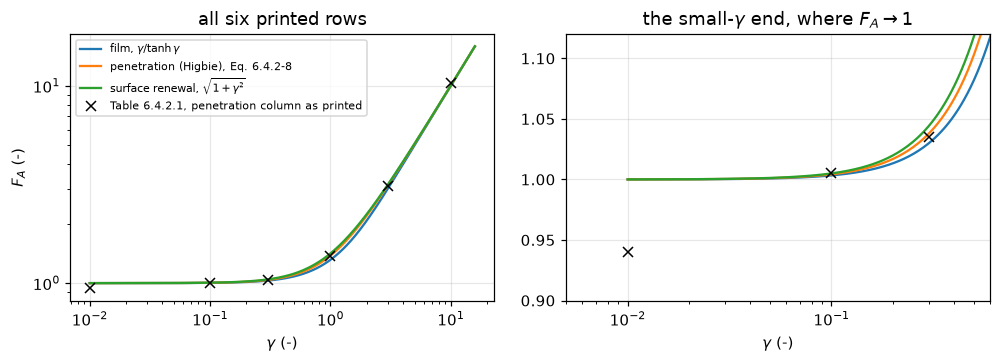


**The surface-renewal column reproduces $\sqrt{1+\gamma^2}$ at
6 of six $\gamma$** (worst
0.50 %, which is rounding). **The
film column is high by one unit in the last printed place at 2 of
six** ($\gamma$ = 0.3: 1.04 printed for 1.0298; $\gamma$ = 3: 3.02 printed for 3.0149),
worst 0.98 %. **The penetration column
disagrees with the closed form printed at the head of its own column at
6 of six**, worst
6.4 %.

Two of those cells are wrong on the table's own evidence, with no computation
needed:

- at $\gamma=0.01$ the printed value is **0.94**, while the other two
  columns of the same row both read 1.00. An enhancement factor below 1
  would mean a reaction that *suppresses* absorption;
- at $\gamma=10$ the printed value is **10.39**, above the
  surface-renewal column's 10.05 in the same row, while Froment's own
  text two paragraphs earlier says the three expressions "differ only by a few
  percent". The closed form is -3.4 %
  from what is printed, and it lies between the other two columns as it should.

`froment_t6421_pen_bracket_violations` = 2 counts exactly those two.
The test is: is the printed penetration cell outside the interval spanned by the
*printed* film and surface-renewal cells of the same row, by more than one unit
(0.01) in the last decimal place those two columns are printed to? It uses
**the printed digits alone** and none of the closed forms.

Froment prints the table "After Beek [1968]"; Beek 1968 is not on disk and was not
consulted, so this is a statement about Froment's printing and nothing more.
**Nothing is repaired**: the CSV holds the cells as printed, and the curves above
are the closed forms, not the cells.


In [9]:
g = np.logspace(-2, 1.2, 400)
fig, ax = plt.subplots(1, 2, figsize=(9.2, 3.4))
for a in ax:
    a.plot(g, FA_film(g), label=r"film, $\gamma/\tanh\gamma$")
    a.plot(g, FA_penetration(g), label="penetration (Higbie), Eq. 6.4.2-8")
    a.plot(g, FA_renewal(g), label=r"surface renewal, $\sqrt{1+\gamma^2}$")
    a.plot(gam, PEN_PR, "kx", ms=7, label="Table 6.4.2.1, penetration column as printed")
    a.set_xscale("log")
    a.set_xlabel(r"$\gamma$ (-)")
ax[0].set_yscale("log")
ax[0].set_ylabel(r"$F_A$ (-)")
ax[0].set_title("all six printed rows")
ax[1].set_xlim(5e-3, 0.6)
ax[1].set_ylim(0.9, 1.12)
ax[1].set_title(r"the small-$\gamma$ end, where $F_A \to 1$")
ax[0].legend(fontsize=7, loc="upper left")
fig.tight_layout()
plt.show()

_film_off = t3.loc[t3["film_off_in_half_units"] > 1, ["gamma", "FA_film_printed", "film_computed"]]
display(Markdown(rf"""
**The surface-renewal column reproduces $\sqrt{{1+\gamma^2}}$ at
{6 - N_OFF["renewal"]} of six $\gamma$** (worst
{claims["froment_t6421_renewal_worst_rel"]*100:.2f} %, which is rounding). **The
film column is high by one unit in the last printed place at {N_OFF["film"]} of
six** ({"; ".join(rf"$\gamma$ = {r.gamma:g}: {r.FA_film_printed:.2f} printed for {r.film_computed:.4f}" for r in _film_off.itertuples())}),
worst {claims["froment_t6421_film_worst_rel"]*100:.2f} %. **The penetration column
disagrees with the closed form printed at the head of its own column at
{N_OFF["penetration"]} of six**, worst
{claims["froment_t6421_penetration_worst_rel"]*100:.1f} %.

Two of those cells are wrong on the table's own evidence, with no computation
needed:

- at $\gamma=0.01$ the printed value is **{PEN_PR[0]:.2f}**, while the other two
  columns of the same row both read {FILM_PR[0]:.2f}. An enhancement factor below 1
  would mean a reaction that *suppresses* absorption;
- at $\gamma=10$ the printed value is **{PEN_PR[-1]:.2f}**, above the
  surface-renewal column's {REN_PR[-1]:.2f} in the same row, while Froment's own
  text two paragraphs earlier says the three expressions "differ only by a few
  percent". The closed form is {claims["froment_t6421_pen_at_gamma_10_rel"]*100:+.1f} %
  from what is printed, and it lies between the other two columns as it should.

`froment_t6421_pen_bracket_violations` = {int(OUT.sum())} counts exactly those two.
The test is: is the printed penetration cell outside the interval spanned by the
*printed* film and surface-renewal cells of the same row, by more than one unit
({BRACKET_TOL}) in the last decimal place those two columns are printed to? It uses
**the printed digits alone** and none of the closed forms.

Froment prints the table "After Beek [1968]"; Beek 1968 is not on disk and was not
consulted, so this is a statement about Froment's printing and nothing more.
**Nothing is repaired**: the CSV holds the cells as printed, and the curves above
are the closed forms, not the cells.
"""))

### 6. BSL's own film-versus-penetration comparison, on a different axis

Chapter 22 compares the same two pictures on something else entirely: the
correction factor $\theta_x$ for a **finite net mass-transfer rate** across the
interface. Eq. 22.8-41 gives $\theta_x=(1-x_{A0})\psi(x_{A0})$ for the penetration
model, with $\psi$ from Arnold's problem (section 20.1, Table 20.1-1), and
Eq. 22.8-42 gives $\theta_x=\frac{1-x_{A0}}{x_{A0}}\ln\frac{1}{1-x_{A0}}$ for the
film. $\varphi$ is obtained here by root-finding BSL's Eq. 20.1-18, never by
reading the printed $\varphi$ back in, so both printed columns of Table 20.1-1 are
independent targets.

In [10]:
def xA0_of_phi(p, with_erf=True):                       # BSL Eq. 20.1-18
    e = (1 + erf(p)) if with_erf else 1.0
    return 1.0 / (1.0 + 1.0 / (np.sqrt(np.pi) * e * p * np.exp(p * p)))


def phi_of_xA0(x, **kw):
    return brentq(lambda p: xA0_of_phi(p, **kw) - x, 1e-12, 10.0, xtol=1e-15, rtol=8.9e-16)


INNER = (tabs["x_A0"] > 0) & (tabs["x_A0"] < 1)
tt, tt_str = tabs[INNER].copy(), tabs_str[INNER.to_numpy()]
xs = tt["x_A0"].to_numpy()
BSL_COLS = {"phi": "phi_20p1_1", "psi": "psi_20p1_1", "theta_pen": "theta_penetration_22p8_2",
            "theta_film": "theta_film_22p8_2"}


def bsl_columns(phi, psi_from_phi=np.sqrt(np.pi), pen=lambda x, psi: (1 - x) * psi,
                film=lambda x: (1 - x) / x * np.log(1 / (1 - x))):
    """Table 20.1-1 and 22.8-2 columns from phi; the arguments are the formulas."""
    psi = phi * psi_from_phi / xs                                    # table head
    return {"phi": phi, "psi": psi, "theta_pen": pen(xs, psi), "theta_film": film(xs)}


def bsl_metrics(cols):
    """Worst relative deviation per column, and the cells off rounding in half units."""
    dev = {k: cols[k] / tt[c].to_numpy() - 1 for k, c in BSL_COLS.items()}
    off = np.concatenate([np.abs(cols[k] - tt[c].to_numpy()) / half_unit(tt_str[c])
                          for k, c in BSL_COLS.items()])
    return dev, off


PHI = np.array([phi_of_xA0(x) for x in xs])
BSL = bsl_columns(PHI)
DEV, OFF = bsl_metrics(BSL)
for k in BSL_COLS:
    tt[f"{k}_computed"], tt[f"{k}_rel"] = BSL[k], DEV[k]
_short = {"phi": "bsl_t2011_phi", "psi": "bsl_t2011_psi", "theta_pen": "bsl_t2282_theta_pen",
          "theta_film": "bsl_t2282_theta_film"}
for k, name in _short.items():
    claims.value(f"{name}_worst_rel", np.abs(DEV[k]).max())
claims.bound("bsl_t2282_theta_pen_minus_psi_dev", np.abs(DEV["theta_pen"] - DEV["psi"]).max(),
             max=1e-14, basis="identity", note="Eq. 22.8-41 makes the two deviation sets equal")
GAP075 = 1 - BSL["theta_pen"][xs == 0.75][0] / BSL["theta_film"][xs == 0.75][0]
claims.value("bsl_t2282_pen_film_gap_at_0p75", GAP075)
N_BSL_OFF = claims.count("bsl_cells_off_rounding", OFF, 1.0, min_margin=1e-3,
                         note="of the twelve interior cells of the four columns")

display(tt[["x_A0", "phi_20p1_1", "phi_computed", "psi_20p1_1", "psi_computed",
            "theta_penetration_22p8_2", "theta_pen_computed",
            "theta_film_22p8_2", "theta_film_computed"]].round(5))

display(Markdown(rf"""
All four printed columns round correctly from the recomputed values:
{N_BSL_OFF} of the {OFF.size} interior cells lie more than half a unit of their last
printed digit away. Worst relative deviations:
{claims["bsl_t2011_phi_worst_rel"]*100:.3f} % on $\varphi$,
{claims["bsl_t2011_psi_worst_rel"]*100:.3f} % on $\psi$,
{claims["bsl_t2282_theta_pen_worst_rel"]*100:.3f} % on the penetration $\theta_x$ and
{claims["bsl_t2282_theta_film_worst_rel"]*100:.3f} % on the film $\theta_x$. Unlike
Froment's Table 6.4.2.1, **BSL's two tables are internally consistent throughout**.

**But the penetration $\theta_x$ is not an independent check.** Eq. 22.8-41 is
$(1-x_{{A0}})\psi$, so the row-by-row deviations of the $\theta_x$ column and of
the $\psi$ column are the same number: they differ by round-off only, below
1e-14 (here {claims["bsl_t2282_theta_pen_minus_psi_dev"]:.0e}). One of the two
metrics is redundant, and the notebook says so rather than counting it twice.

The physics BSL draws from the table: "the penetration model predicts a stronger
correction $\theta_x$ for net mass transfer than does the film model. This is in
part because the net flow thickens the boundary layer, an effect that the film
model does not consider." The gap reaches {GAP075*100:.1f} % at $x_{{A0}}=0.75$.
The two rows at $x_{{A0}}=0$ and $x_{{A0}}=1$ are the two analytic limits of both
models and agree by construction, so only the interior rows carry information; and
$\theta_x$ is a high-flux correction, **not** the $\mathscr{{D}}^{{n}}$ question.
"""))

,x_A0,phi_20p1_1,phi_computed,psi_20p1_1,psi_computed,theta_penetration_22p8_2,theta_pen_computed,theta_film_22p8_2,theta_film_computed
1,0.25,0.1562,0.15622,1.108,1.10754,0.831,0.83065,0.863,0.86305
2,0.50,0.3578,0.35783,1.268,1.26849,0.634,0.63425,0.693,0.69315
3,0.75,0.6618,0.66176,1.564,1.56392,0.391,0.39098,0.462,0.46210



All four printed columns round correctly from the recomputed values:
0 of the 12 interior cells lie more than half a unit of their last
printed digit away. Worst relative deviations:
0.010 % on $\varphi$,
0.042 % on $\psi$,
0.042 % on the penetration $\theta_x$ and
0.021 % on the film $\theta_x$. Unlike
Froment's Table 6.4.2.1, **BSL's two tables are internally consistent throughout**.

**But the penetration $\theta_x$ is not an independent check.** Eq. 22.8-41 is
$(1-x_{A0})\psi$, so the row-by-row deviations of the $\theta_x$ column and of
the $\psi$ column are the same number: they differ by round-off only, below
1e-14 (here 1e-16). One of the two
metrics is redundant, and the notebook says so rather than counting it twice.

The physics BSL draws from the table: "the penetration model predicts a stronger
correction $\theta_x$ for net mass transfer than does the film model. This is in
part because the net flow thickens the boundary layer, an effect that the film
model does not consider." The gap reaches 15.4 % at $x_{A0}=0.75$.
The two rows at $x_{A0}=0$ and $x_{A0}=1$ are the two analytic limits of both
models and agree by construction, so only the interior rows carry information; and
$\theta_x$ is a high-flux correction, **not** the $\mathscr{D}^{n}$ question.


### 7. When is the penetration approximation actually good?

BSL replaces Eq. 18.5-7 by Eq. 18.5-11 with two arguments at once: $A$ "has the
impression" the film moves at $v_{\max}$, and $A$ does not "sense" the wall. The
solver can switch those separately, which turns the sentence into two numbers.
Write

$$r_{\rm full}(\Lambda)=\frac{\Phi_{\rm full}}{\Phi_{\rm pen}},\qquad
r_{\rm wall}(\Lambda)=\frac{\Phi_{\rm plug,\,wall}}{\Phi_{\rm pen}},\qquad
r_{\rm profile}(\Lambda)=\frac{\Phi_{\rm full}}{\Phi_{\rm plug,\,wall}},$$

so that $r_{\rm full}=r_{\rm wall}\,r_{\rm profile}$ exactly. $r_{\rm wall}$ is
taken from the **exact eigenfunction series** of *Validation 2*; $r_{\rm profile}$
is a ratio of two solves on the same grid with the same steps. Both choices are
measured below: how large the solver's own error is against the wall effect, and
how much of it cancels in the ratio.

find_roots on [1e-3, 0.5], 8 log-spaced scan points: one root, Lambda* = 0.056426


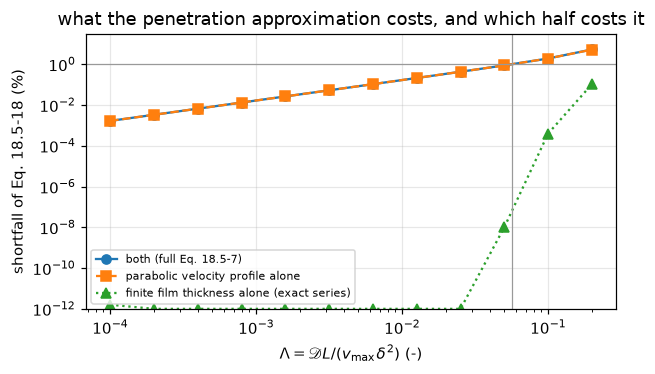

In [11]:
NX, NT, STR = 600, 800, 6.0                # production film grid and step count


def phi_film(Lam, profile, n_x=NX, n_t=NT, which="extrapolated", **kw):
    """Mixing cup on the film (wall at xi = 1): Richardson-extrapolated, or ``raw``."""
    return phi_extrapolated(Lam, n_t, XI=1.0, n_x=n_x, stretch=STR, profile=profile,
                            **kw)[which]


def r_profile(Lam, n_x=NX, n_t=NT, n_x_plug=None, which="extrapolated"):
    """Phi(full) / Phi(plug flow with the same wall), both on the same grid by default."""
    return (phi_film(Lam, "parabolic", n_x, n_t, which)
            / phi_film(Lam, "plug", n_x if n_x_plug is None else n_x_plug, n_t, which))


def r_wall(Lam, n_terms=20000):
    """Exact: the series with the wall over the semi-infinite answer."""
    return phi_wall_series(Lam, n_terms) / phi_penetration(Lam)


def r_full(Lam, **kw):
    return r_wall(Lam) * r_profile(Lam, **kw)


lams = np.logspace(-4, -0.7, 12)
rp = np.array([r_profile(l) for l in lams])
rw = np.array([r_wall(l) for l in lams])
rf = rw * rp

L_MARK = 0.1
PE = 1 - r_profile(L_MARK)
WE = 1 - r_wall(L_MARK)
claims.value("profile_effect_at_lambda_0p1", PE)
claims.value("wall_effect_series_at_lambda_0p1", WE)
claims.value("profile_over_wall_effect_at_lambda_0p1", PE / WE)
WE_SOLVER = 1 - phi_film(L_MARK, "plug") / phi_penetration(L_MARK)
claims.value("wall_effect_solver_at_lambda_0p1", WE_SOLVER)

# The 1 % threshold, root-found with a scan that reports every sign change.
ROOTS = find_roots(lambda l: r_full(l) - 0.99, 1e-3, 0.5, n_scan=8, log=True, xtol=1e-10)
claims.exact("lambda_star_roots_in_range", len(ROOTS["roots"]))
lam_star = ROOTS["roots"][0]
claims.value("lambda_star_1pct", lam_star, rtol=1e-3)
claims.value("pen_depth_over_delta_at_1pct", np.sqrt(4 * lam_star), rtol=1e-3)
delta_star = np.sqrt(D_cl * L / (v_max * lam_star))
claims.value("delta_star_18A4_um", delta_star * 1e4, rtol=1e-3)
# The same threshold read off sweeps by interpolation, for the break table.
lam_star_swept = float(np.interp(-0.99, -rf, lams))
lams_coarse = np.logspace(-4, -0.7, 5)
lam_star_swept_coarse = float(np.interp(-0.99, -np.array([r_full(l) for l in lams_coarse]),
                                        lams_coarse))
print(f"find_roots on [1e-3, 0.5], 8 log-spaced scan points: {ROOTS['message']}, "
      f"Lambda* = {lam_star:.6f}")

fig, ax = plt.subplots(figsize=(5.8, 3.5))
ax.loglog(lams, 100 * (1 - rf), "o-", label="both (full Eq. 18.5-7)")
ax.loglog(lams, 100 * (1 - rp), "s--", label="parabolic velocity profile alone")
ax.loglog(lams, 100 * np.maximum(1 - rw, 1e-14), "^:",
          label="finite film thickness alone (exact series)")
ax.axhline(1.0, color="0.6", lw=0.8)
ax.axvline(lam_star, color="0.6", lw=0.8)
ax.set_ylim(1e-12, 30)
ax.set_xlabel(r"$\Lambda = \mathscr{D}L/(v_{\max}\delta^2)$ (-)")
ax.set_ylabel("shortfall of Eq. 18.5-18 (%)")
ax.set_title("what the penetration approximation costs, and which half costs it")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

**How accurate are these numbers?** Three measurements, on grids refined from
the production 600 cells with the step extrapolation kept: the solver's own
estimate of the wall effect on a grid ladder (its Richardson limit against the
series), the profile effect at 600 and at 2400 cells, and $r_{\rm full}$ at
$\Lambda^{\ast}$ on the refined grid, converted to a shift of $\Lambda^{\ast}$ with the
local slope.

In [12]:
WALL_LADDER = (600, 1200, 2400, 4800)


def wall_ladder(n_t=1600, joint=False):
    """Plug flow with the wall at Lambda = 0.1 on a grid ladder; ``joint`` refines the
    steps with the grid and drops the extrapolation (both axes at once)."""
    def cup(n):
        if joint:
            return Film(L_MARK, n_x=n, stretch=STR, profile="plug").march(n // 3)["cup"]
        return phi_film(L_MARK, "plug", n_x=n, n_t=n_t)
    return observed_orders(cup, WALL_LADDER)


WALL_NT = (1600, 6400)                     # two step pairs: n_t/2 n_t extrapolated
WLS = {n: wall_ladder(n_t=n) for n in WALL_NT}
WL = WLS[WALL_NT[-1]]
WE_LAD = {n: 1 - WLS[n]["extrapolated"] / phi_penetration(L_MARK) for n in WALL_NT}
WE_REFINED = WE_LAD[WALL_NT[-1]]
WE_GAP = {n: abs(WE_LAD[n] / WE - 1) for n in WALL_NT}
for n in WALL_NT:
    print(f"plug flow with the wall, Lambda = 0.1, steps extrapolated from {n}/{2 * n}:")
    for nx, v in zip(WALL_LADDER, WLS[n]["values"]):
        print(f"   n_x = {nx:5d}   1 - Phi/Phi_pen = {1 - v / phi_penetration(L_MARK):.4e}")
    print(f"   grid orders from successive differences: {np.round(WLS[n]['orders'], 3)}; "
          f"grid limit {WE_LAD[n]:.4e}, {WE_GAP[n]:.1e} from the series")
WE_GAP_DROP = WE_GAP[WALL_NT[0]] / WE_GAP[WALL_NT[-1]]
claims.bound("wall_ladder_grid_order", WL["orders"][-1], min=1.9, max=2.1, basis="theory",
             note="successive differences, n_x 1200/2400/4800")
claims.value("wall_effect_solver_refined_at_lambda_0p1", WE_REFINED, rtol=1e-3)
claims.bound("wall_effect_refined_vs_series_rel", WE_GAP[WALL_NT[-1]], max=1e-3,
             basis="chosen", note="grid limit at steps 6400/12800 against the series")
claims.bound("wall_refined_gap_drop_steps_x4", WE_GAP_DROP, min=8, max=32, basis="theory",
             note="the remaining gap is the extrapolated step error, second order: 16 for 4x steps")

PE_2400 = 1 - r_profile(L_MARK, n_x=2400)
claims.bound("profile_effect_grid_change_rel", abs(PE_2400 / PE - 1), max=1e-4, basis="chosen",
             note="profile effect at 600 against 2400 cells, steps extrapolated")


def lam_star_shift(**kw):
    """Relative shift of Lambda* implied by r_full(Lambda*) under other numerics."""
    h = 1e-3 * lam_star
    slope = (r_full(lam_star + h) - r_full(lam_star - h)) / (2 * h)
    return abs((r_full(lam_star, **kw) - 0.99) / slope) / lam_star


LS_SHIFT = lam_star_shift(n_x=2400, n_t=1600)
claims.bound("lambda_star_grid_shift_rel", LS_SHIFT, max=1e-4, basis="chosen",
             note="r_full at Lambda* on 2400 cells and 1600/3200 steps")

display(Markdown(rf"""
**The two halves of BSL's argument are not equally load-bearing.** At
$\Lambda={L_MARK}$, where the penetration depth has reached
$\sqrt{{4\Lambda}}$ = {np.sqrt(4*L_MARK):.2f} of the film thickness, the finite
film costs {WE*100:.5f} % while the parabolic velocity profile costs
{PE*100:.2f} %, a factor **{PE/WE:.0f}** between them.

The reason is visible in the series: a reflecting wall only returns solute that a
semi-infinite film would have retained anyway, so what is lost is only the far tail
of the erfc profile, the part that would have reached beyond about *twice* the
film thickness, and the series puts that at {WE:.1e} here. What actually breaks
Eq. 18.5-18 is that the liquid *below* the surface moves more slowly than
$v_{{\max}}$ and therefore has longer to load up.

**Why the wall effect comes from the series.** On the production grid of {NX}
cells the solver's estimate is {WE_SOLVER:.2e}, a factor
{WE_SOLVER/WE:.1f} above the exact {WE:.2e}: its grid error there (*Validation 2*)
is larger than the effect. That is a property of the grid, not of the solver.
Refined to {WALL_LADDER[-1]} cells the grid error falls at order
{WL["orders"][-1]:.2f}. With steps 6400/12800 the Richardson limit of the grid
ladder gives {WE_REFINED:.4e}, within {WE_GAP[WALL_NT[-1]]*100:.3f} % of the
series; with steps 1600/3200 the gap is {WE_GAP[WALL_NT[0]]*100:.2f} %, and it
falls {WE_GAP_DROP:.0f} times for four times the steps, so what remains is the
extrapolated step error, not a difference between solver and series. The series is
the cheaper route, and the solver confirms it.

**The ratio cancels the grid error.** $r_{{\rm profile}}$ divides two solves on the
same grid with the same steps, each with a grid error of a few parts per million.
Their errors nearly cancel: the profile effect at {NX} cells differs from its value
at 2400 cells by {abs(PE_2400/PE - 1):.1e} relative (bound 1e-4). Solving the two
halves of the ratio on different grids breaks the cancellation (break table).

**The 1 % threshold, root-found rather than read off the sweep:**
$\Lambda^{{\ast}}$ = **{lam_star:.5f}** (one sign change on the scanned range, located
by `pymrm.checks.find_roots`), i.e. Eq. 18.5-18 is within 1 % of the full
Eq. 18.5-7 for any film in which the penetration depth stays below
**{np.sqrt(4*lam_star):.3f}$\,\delta$**. On 2400 cells with 1600/3200 steps,
$r_{{\rm full}}(\Lambda^{{\ast}})$ moves $\Lambda^{{\ast}}$ by
{LS_SHIFT:.1e} relative. For Problem 18A.4's column that means any water film
thicker than **{delta_star*1e4:.0f} um**; the penetration depth there is
{pen_depth_film*1e4:.1f} um. Problem 18A.4 prints no film thickness, no viscosity
and no flow rate, so **this page does not state a correction for that column**: it
states the threshold, which is what the printed data support.

A sampled crossing is not a root: reading the threshold off the twelve-point sweep
plotted above, or off a five-point sweep over the same range, moves it by the
amounts the break table prints. Neither is what is reported.
"""))

plug flow with the wall, Lambda = 0.1, steps extrapolated from 1600/3200:
   n_x =   600   1 - Phi/Phi_pen = 1.0343e-05
   n_x =  1200   1 - Phi/Phi_pen = 5.5816e-06
   n_x =  2400   1 - Phi/Phi_pen = 4.3912e-06
   n_x =  4800   1 - Phi/Phi_pen = 4.0935e-06
   grid orders from successive differences: [2. 2.]; grid limit 3.9943e-06, 1.8e-03 from the series
plug flow with the wall, Lambda = 0.1, steps extrapolated from 6400/12800:
   n_x =   600   1 - Phi/Phi_pen = 1.0337e-05
   n_x =  1200   1 - Phi/Phi_pen = 5.5751e-06
   n_x =  2400   1 - Phi/Phi_pen = 4.3846e-06
   n_x =  4800   1 - Phi/Phi_pen = 4.0870e-06
   grid orders from successive differences: [2. 2.]; grid limit 3.9877e-06, 1.0e-04 from the series



**The two halves of BSL's argument are not equally load-bearing.** At
$\Lambda=0.1$, where the penetration depth has reached
$\sqrt{4\Lambda}$ = 0.63 of the film thickness, the finite
film costs 0.00040 % while the parabolic velocity profile costs
1.92 %, a factor **4810** between them.

The reason is visible in the series: a reflecting wall only returns solute that a
semi-infinite film would have retained anyway, so what is lost is only the far tail
of the erfc profile, the part that would have reached beyond about *twice* the
film thickness, and the series puts that at 4.0e-06 here. What actually breaks
Eq. 18.5-18 is that the liquid *below* the surface moves more slowly than
$v_{\max}$ and therefore has longer to load up.

**Why the wall effect comes from the series.** On the production grid of 600
cells the solver's estimate is 1.04e-05, a factor
2.6 above the exact 3.99e-06: its grid error there (*Validation 2*)
is larger than the effect. That is a property of the grid, not of the solver.
Refined to 4800 cells the grid error falls at order
2.00. With steps 6400/12800 the Richardson limit of the grid
ladder gives 3.9877e-06, within 0.010 % of the
series; with steps 1600/3200 the gap is 0.18 %, and it
falls 17 times for four times the steps, so what remains is the
extrapolated step error, not a difference between solver and series. The series is
the cheaper route, and the solver confirms it.

**The ratio cancels the grid error.** $r_{\rm profile}$ divides two solves on the
same grid with the same steps, each with a grid error of a few parts per million.
Their errors nearly cancel: the profile effect at 600 cells differs from its value
at 2400 cells by 5.4e-06 relative (bound 1e-4). Solving the two
halves of the ratio on different grids breaks the cancellation (break table).

**The 1 % threshold, root-found rather than read off the sweep:**
$\Lambda^{\ast}$ = **0.05643** (one sign change on the scanned range, located
by `pymrm.checks.find_roots`), i.e. Eq. 18.5-18 is within 1 % of the full
Eq. 18.5-7 for any film in which the penetration depth stays below
**0.475$\,\delta$**. On 2400 cells with 1600/3200 steps,
$r_{\rm full}(\Lambda^{\ast})$ moves $\Lambda^{\ast}$ by
1.4e-06 relative. For Problem 18A.4's column that means any water film
thicker than **105 um**; the penetration depth there is
49.7 um. Problem 18A.4 prints no film thickness, no viscosity
and no flow rate, so **this page does not state a correction for that column**: it
states the threshold, which is what the printed data support.

A sampled crossing is not a root: reading the threshold off the twelve-point sweep
plotted above, or off a five-point sweep over the same range, moves it by the
amounts the break table prints. Neither is what is reported.


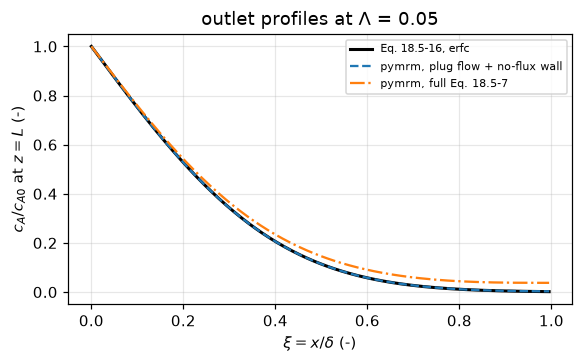

In [13]:
# Profiles: the full problem against Eq. 18.5-16, at a Lambda where they part.
LAM_P = 0.05
f_full = Film(LAM_P, n_x=NX, stretch=STR, profile="parabolic")
f_plug = Film(LAM_P, n_x=NX, stretch=STR, profile="plug")
OUT_FULL = f_full.march(1600, record_flux=True)
xi = f_full.x_c

fig, ax = plt.subplots(figsize=(5.4, 3.4))
ax.plot(xi, erfc(xi / np.sqrt(4 * LAM_P)), "k-", lw=2, label=r"Eq. 18.5-16, $\mathrm{erfc}$")
ax.plot(xi, f_plug.march(1600)["u"], "--", label="pymrm, plug flow + no-flux wall")
ax.plot(xi, OUT_FULL["u"], "-.", label="pymrm, full Eq. 18.5-7")
ax.set_xlabel(r"$\xi = x/\delta$ (-)")
ax.set_ylabel(r"$c_A/c_{A0}$ at $z = L$ (-)")
ax.set_title(rf"outlet profiles at $\Lambda$ = {LAM_P}")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

## Validation

Four checks that can fail, and a break table. Every check below compares the
solver with something that shares no code with it (a closed form, an exact
series), with its own refinement, or with an identity of the scheme that a
defect can break.

### 1. The penetration branch against BSL's own closed forms

With the capacity set to 1 and the domain deep, the solver is Eq. 18.5-11 and must
reproduce Eq. 18.5-16 pointwise and $\Phi=\sqrt{4\Lambda/\pi}$ (equivalently
Eq. 18.5-18) in the integral. The march also integrates the interfacial flux over
$\zeta$, read at every step with `compute_boundary_values`: under backward Euler
on a conservative finite-volume scheme that integral equals the outlet mixing cup
(BSL's Problem 18C.3 identity) to round-off, whatever the physics.

In [14]:
LAM_V, NXV = 1e-2, 800
XIV = 12 * np.sqrt(4 * LAM_V)
V_FILM = dict(XI=XIV, n_x=NXV, stretch=4.0, profile="plug")
fv = Film(LAM_V, **V_FILM)
OUT_V = fv.march(1600, record_flux=True)
Phi_raw, Phi_half = OUT_V["cup"], fv.march(800)["cup"]
Phi_ext = 2 * Phi_raw - Phi_half


def profile_err(film, u, Lam=LAM_V):
    return float(np.abs(u - erfc(film.x_c / np.sqrt(4 * Lam))).max())


claims.value("pen_profile_vs_eq18516_max_abs", profile_err(fv, OUT_V["u"]))
claims.value("pen_uptake_vs_eq18518_rel", rel(Phi_ext, phi_penetration(LAM_V)))
claims.value("pen_uptake_vs_eq18518_raw_rel", rel(Phi_raw, phi_penetration(LAM_V)))
claims.bound("mixing_cup_vs_flux_integral_rel", abs(rel(OUT_V["flux_integral"], Phi_raw)),
             max=1e-11, basis="identity",
             note="backward Euler on a conservative scheme: inventory = flux integral")
FULL_ID = abs(rel(OUT_FULL["flux_integral"], OUT_FULL["cup"]))
claims.bound("mixing_cup_vs_flux_integral_full_rel", FULL_ID, max=1e-10, basis="identity",
             note="the same identity in the full model, cup weighted by 1 - xi^2; round-off "
                  "accumulated over 1600 steps, 2.8e-12 on three BLAS kernels, bound 35x above")

display(Markdown(rf"""
- outlet profile against Eq. 18.5-16, worst absolute deviation in $c_A/c_{{A0}}$:
  **{claims["pen_profile_vs_eq18516_max_abs"]:.3e}** (raw, $n_t$ = 1600; the
  marching error dominates it)
- outlet uptake against $\sqrt{{4\Lambda/\pi}}$:
  **{claims["pen_uptake_vs_eq18518_rel"]:+.3e}** extrapolated,
  {claims["pen_uptake_vs_eq18518_raw_rel"]:+.3e} raw at $n_t$ = 1600
- outlet mixing cup against the marched integral of the interfacial flux: below
  1e-11 relative here (here {claims["mixing_cup_vs_flux_integral_rel"]:.0e}), and
  below 1e-10 in the full model at $\Lambda$ = {LAM_P} (here {FULL_ID:.0e})

The third is an identity of the scheme, not a test of the physics: it holds for any
$\Lambda$ and any grid. It still tests something, the boundary reading and the
capacity weight of the cup, and the break table moves it by leaving the
$(1-\xi^2)$ weight out of the cup in the full model.
"""))


- outlet profile against Eq. 18.5-16, worst absolute deviation in $c_A/c_{A0}$:
  **1.148e-04** (raw, $n_t$ = 1600; the
  marching error dominates it)
- outlet uptake against $\sqrt{4\Lambda/\pi}$:
  **-2.834e-06** extrapolated,
  -1.070e-04 raw at $n_t$ = 1600
- outlet mixing cup against the marched integral of the interfacial flux: below
  1e-11 relative here (here 3e-13), and
  below 1e-10 in the full model at $\Lambda$ = 0.05 (here 3e-12)

The third is an identity of the scheme, not a test of the physics: it holds for any
$\Lambda$ and any grid. It still tests something, the boundary reading and the
capacity weight of the cup, and the break table moves it by leaving the
$(1-\xi^2)$ weight out of the cup in the full model.


### 2. The wall branch against an exact series

Plug flow with a no-flux wall has a closed solution by separation of variables
that the books do not print, and which shares nothing with the solver: with
$v=1-u$, $v(0)=0$, $v_\xi(1)=0$, $v(\xi,0)=1$,

$$v = \sum_{n\ge0}\frac{2}{\lambda_n}\sin(\lambda_n\xi)\,e^{-\Lambda\lambda_n^{2}\zeta},
\qquad \lambda_n=(n+\tfrac12)\pi
\qquad\Longrightarrow\qquad
\Phi = 1-\sum_{n\ge0}\frac{2}{\lambda_n^{2}}e^{-\Lambda\lambda_n^{2}}.$$

Its $\Lambda\to0$ limit is $\sqrt{4\Lambda/\pi}$, which is a real check on both:
the series is built from sines and the closed form from an error function.

In [15]:
WALL_LAMS = (1e-3, 1e-2, 1e-1)


def wall_errors(n_x=NX, n_t=NT, extrapolate=True, wall="noflux"):
    """Relative deviation of the plug-flow-with-wall cup from the series."""
    out = []
    for Lam in WALL_LAMS:
        ph = phi_extrapolated(Lam, n_t, n_x=n_x, stretch=STR, profile="plug", wall=wall)
        out.append(rel(ph["extrapolated"] if extrapolate else ph["raw"], phi_wall_series(Lam)))
    return np.array(out)


WERR, WERR_2 = wall_errors(), wall_errors(n_x=2 * NX)
WRATIO = np.abs(WERR / WERR_2)
claims.value("wall_series_vs_pymrm_worst_rel", np.abs(WERR).max())
claims.bound("wall_series_err_ratio_grid_doubled_min", WRATIO.min(), min=3.5, max=4.5,
             basis="theory", note="second-order grid error: 4 when n_x doubles")
print(f"{'Lambda':>8} {'rel dev, ' + str(NX) + ' cells':>20} {'rel dev, ' + str(2*NX) + ' cells':>21}"
      f" {'ratio':>6} {'wall effect (series)':>21}")
for Lam, e1, e2 in zip(WALL_LAMS, WERR, WERR_2):
    we = 1 - r_wall(Lam)
    shown = f"{we:21.3e}" if we > 1e-12 else f"{'below 1e-12':>21}"
    print(f"{Lam:8.0e} {e1:20.2e} {e2:21.2e} {e1/e2:6.2f} {shown}")

display(Markdown(rf"""
Worst deviation between the finite-volume march and the exact series over three
decades of $\Lambda$: **{np.abs(WERR).max():.2e}** on {NX} cells. It is the grid
error: doubling the cells divides it by {WRATIO.min():.2f} to {WRATIO.max():.2f}
at every $\Lambda$, the second-order factor 4, while the marching error is removed
by the step extrapolation (*Validation 3*). The last column is why the wall
effect comes from the series in *Results 7*: at $\Lambda=10^{{-3}}$ and $10^{{-2}}$
the series puts it at round-off (below 1e-12), and at $\Lambda=0.1$ it is below the
production grid error.
"""))

  Lambda   rel dev, 600 cells   rel dev, 1200 cells  ratio  wall effect (series)
   1e-03            -7.15e-06             -1.81e-06   3.95           below 1e-12
   1e-02            -6.56e-06             -1.66e-06   3.94           below 1e-12
   1e-01            -6.38e-06             -1.62e-06   3.95             3.987e-06



Worst deviation between the finite-volume march and the exact series over three
decades of $\Lambda$: **7.15e-06** on 600 cells. It is the grid
error: doubling the cells divides it by 3.94 to 3.95
at every $\Lambda$, the second-order factor 4, while the marching error is removed
by the step extrapolation (*Validation 3*). The last column is why the wall
effect comes from the series in *Results 7*: at $\Lambda=10^{-3}$ and $10^{-2}$
the series puts it at round-off (below 1e-12), and at $\Lambda=0.1$ it is below the
production grid error.


### 3. Both axes refined, with observed orders, and the integrator

The marching step and the grid are refined separately, on the *Validation 1*
case, and each order is taken from **successive differences** of three levels
(`pymrm.checks.observed_orders`), which cancel the other axis's error as long as
it is the same on every rung: the step ladder runs on one grid, and the grid
ladder uses the step-extrapolated $\Phi$ at fixed step counts. The reference for
the step error is the limit of a ladder of *extrapolated* values (order 2), not
a first-order fit to the raw values. This case is the deep plug-flow solve of
*Validation 1*; the production film is measured after it.

In [16]:
STEP_LADDER, GRID_LADDER = (200, 400, 800, 1600, 3200, 6400), (100, 200, 400, 800, 1600)
ROUNDOFF = 2e-13      # relative round-off of a mixing cup: n_x eps, 2e-14..2e-13 for n_x 1e2..1e3


def step_ladder(n_x=NXV):
    f = Film(LAM_V, **{**V_FILM, "n_x": n_x})
    cache = {n: f.march(n)["cup"] for n in STEP_LADDER}
    return observed_orders(lambda n: cache[n], STEP_LADDER), cache


def grid_ladder(stretch=4.0, n_t=1600, against_exact=False):
    def cup(n):
        if against_exact:     # the raw cup, read against the exact value below
            return Film(LAM_V, **{**V_FILM, "n_x": n, "stretch": stretch}).march(n_t)["cup"]
        return phi_extrapolated(LAM_V, n_t, **{**V_FILM, "n_x": n, "stretch": stretch})["extrapolated"]
    return observed_orders(cup, GRID_LADDER)


def orders_vs_exact(values, ns):
    """The tempting alternative: orders from errors against the exact value."""
    e = np.abs(np.array(values) / phi_penetration(LAM_V) - 1)
    return np.log(e[:-1] / e[1:]) / np.log(ns[1] / ns[0])


SL, SL_CUPS = step_ladder()
RICH_LADDER = STEP_LADDER[:-1]
RL = observed_orders(lambda n: 2 * SL_CUPS[2 * n] - SL_CUPS[n], RICH_LADDER)
REF_STEP = RL["extrapolated"]          # the step limit on this grid, from order-2 values
GL = grid_ladder()
TIME_ERR_1600 = abs(SL_CUPS[1600] / REF_STEP - 1)
SPACE_ERR = {n: abs(v / GL["extrapolated"] - 1) for n, v in zip(GRID_LADDER, GL["values"])}
RICH_ERR = {n: abs((2 * SL_CUPS[2 * n] - SL_CUPS[n]) / REF_STEP - 1) for n in (800, 1600)}
GL_LIMIT_VS_EXACT = abs(GL["extrapolated"] / phi_penetration(LAM_V) - 1)

print(f"steps, n_x = {NXV} (raw backward Euler):")
for i, n in enumerate(STEP_LADDER):
    o = f"{SL['orders'][i-2]:7.3f}" if i >= 2 else ""
    print(f"   n_t = {n:5d}   Phi = {SL_CUPS[n]:.10f}   {o}")
print(f"grid, steps extrapolated from {1600}/{3200}:")
for i, n in enumerate(GRID_LADDER):
    o = f"{GL['orders'][i-2]:7.3f}" if i >= 2 else ""
    print(f"   n_x = {n:5d}   Phi = {GL['values'][i]:.10f}   {o}")

claims.bound("time_order", SL["orders"][-1], min=0.95, max=1.05, basis="theory",
             note="backward Euler, successive differences, n_t 1600/3200/6400")
claims.bound("time_order_extrapolated", RL["orders"][-1], min=1.9, max=2.1, basis="theory",
             note="extrapolated values 2 Phi(2n) - Phi(n), n 400/800/1600 to 3200")
claims.bound("time_order_min", min(SL["orders"]), min=0.95, max=1.05, basis="theory",
             note="all triples from n_t = 200")
claims.bound("space_order", GL["orders"][-1], min=1.9, max=2.1, basis="theory",
             note="successive differences, n_x 400/800/1600")
claims.bound("space_order_min", min(GL["orders"]), min=1.9, max=2.1, basis="theory",
             note="all triples from n_x = 100")
claims.bound("time_ladder_finest_diff_over_roundoff",
             abs(SL_CUPS[3200] - SL_CUPS[1600]) / (ROUNDOFF * SL_CUPS[3200]), min=1e3,
             basis="theory", note="finest step difference against round-off of the cup")
claims.bound("space_ladder_finest_diff_over_roundoff",
             abs(GL["values"][-1] - GL["values"][-2]) / (ROUNDOFF * GL["values"][-1]), min=1e3,
             basis="theory", note="finest grid difference against round-off of the cup")
claims.value("time_err_n1600", TIME_ERR_1600)
claims.value("space_err_n400", SPACE_ERR[400])
claims.value("space_err_n800", SPACE_ERR[800])
claims.bound("time_err_extrapolated_n1600", RICH_ERR[1600], max=1e-7, basis="chosen",
             note="2 Phi(3200) - Phi(1600) against the limit of the extrapolated ladder")
claims.bound("time_err_extrapolated_n800", RICH_ERR[800], max=1e-7, basis="chosen",
             note="the production pair 800/1600, same reference")
claims.bound("grid_ladder_limit_vs_exact", GL_LIMIT_VS_EXACT, max=1e-7, basis="chosen",
             note="the grid ladder's limit against sqrt(4 Lam/pi): what neither axis removes")

display(Markdown(rf"""
Observed orders: **{SL["orders"][-1]:.3f}** in the marching step (backward Euler,
first order; every triple from $n_t$ = 200 within
{min(SL["orders"]):.3f} to {max(SL["orders"]):.3f}) and **{GL["orders"][-1]:.3f}**
in the grid (second order on the stretched mesh; every triple within
{min(GL["orders"]):.3f} to {max(GL["orders"]):.3f}).

**Which error is the larger depends on whether the step is extrapolated.** Raw,
the marching step dominates: {TIME_ERR_1600:.2e} at $n_t$ = 1600, against a grid
error of {SPACE_ERR[NXV]:.2e} on the {NXV} cells used here. Extrapolated, the
step error converges at order {RL["orders"][-1]:.2f} and is below 1e-7 for both
the 800/1600 pair the page uses in production (here {RICH_ERR[800]:.1e}) and
1600/3200 (here {RICH_ERR[1600]:.1e}), and the grid error is what is left. The grid ladder's own limit agrees with
$\sqrt{{4\Lambda/\pi}}$ to below 1e-7 (here {GL_LIMIT_VS_EXACT:.1e}), so neither
the far boundary nor anything else the ladders cannot see is larger.
"""))

steps, n_x = 800 (raw backward Euler):
   n_t =   200   Phi = 0.1127436870   
   n_t =   400   Phi = 0.1127906143   
   n_t =   800   Phi = 0.1128141001     0.999
   n_t =  1600   Phi = 0.1128258485     0.999
   n_t =  3200   Phi = 0.1128317241     1.000
   n_t =  6400   Phi = 0.1128346622     1.000
grid, steps extrapolated from 1600/3200:
   n_x =   100   Phi = 0.1128177484   
   n_x =   200   Phi = 0.1128328647   
   n_x =   400   Phi = 0.1128366519     1.997
   n_x =   800   Phi = 0.1128375997     1.999
   n_x =  1600   Phi = 0.1128378367     1.999



Observed orders: **1.000** in the marching step (backward Euler,
first order; every triple from $n_t$ = 200 within
0.999 to 1.000) and **1.999**
in the grid (second order on the stretched mesh; every triple within
1.997 to 1.999).

**Which error is the larger depends on whether the step is extrapolated.** Raw,
the marching step dominates: 1.04e-04 at $n_t$ = 1600, against a grid
error of 2.80e-06 on the 800 cells used here. Extrapolated, the
step error converges at order 2.00 and is below 1e-7 for both
the 800/1600 pair the page uses in production (here 3.3e-08) and
1600/3200 (here 8.1e-09), and the grid error is what is left. The grid ladder's own limit agrees with
$\sqrt{4\Lambda/\pi}$ to below 1e-7 (here 7.9e-09), so neither
the far boundary nor anything else the ladders cannot see is larger.


**The same budget on the production film.** For the full film on 600 cells with
steps 800/1600, the step error of the extrapolated value is estimated from the
change between the 800/1600 and 1600/3200 pairs, and the grid error from the
change between 600 and 1200 cells, both scaled by their order (2 and 2), over
$\Lambda$ from $10^{-4}$ to 0.2.

In [17]:
BUDGET_LAMS = np.logspace(-4, np.log10(0.2), 6)


def production_budget(Lam, n_t=NT):
    """(grid error, step error) of the extrapolated full-film cup at production settings."""
    f6, f12 = Film(Lam, n_x=NX, stretch=STR), Film(Lam, n_x=2 * NX, stretch=STR)
    c = {n: f6.march(n)["cup"] for n in (n_t, 2 * n_t, 4 * n_t)}
    e1, e2 = 2 * c[2 * n_t] - c[n_t], 2 * c[4 * n_t] - c[2 * n_t]
    g = 2 * f12.march(2 * n_t)["cup"] - f12.march(n_t)["cup"]
    return abs(e1 - g) * 4 / 3 / e1, abs(e1 - e2) * 4 / 3 / e1


BUDGET = np.array([production_budget(l) for l in BUDGET_LAMS])
BUDGET_RATIO = BUDGET[:, 0] / BUDGET[:, 1]
print(f"{'Lambda':>8} {'grid err':>10} {'step err':>10} {'ratio':>8}")
for l, (ge, se), r in zip(BUDGET_LAMS, BUDGET, BUDGET_RATIO):
    print(f"{l:8.1e} {ge:10.1e} {se:10.1e} {r:8.0f}")
claims.bound("production_grid_over_step_err_min", BUDGET_RATIO.min(), min=10, basis="chosen",
             note="full film, 600 cells, steps 800/1600 extrapolated, Lambda 1e-4 to 0.2")
display(Markdown(rf"""
At every $\Lambda$ of the sweep the grid error of the production value is more than
10 times its extrapolated step error (here at least {BUDGET_RATIO.min():.0f} times):
the statement of the case above holds for the production film too.
"""))

  Lambda   grid err   step err    ratio
 1.0e-04    9.0e-06    3.3e-08      276
 4.6e-04    7.5e-06    3.3e-08      231
 2.1e-03    6.9e-06    3.3e-08      210
 9.6e-03    6.5e-06    3.3e-08      199
 4.4e-02    6.4e-06    3.2e-08      198
 2.0e-01    5.8e-06    1.2e-07       46



At every $\Lambda$ of the sweep the grid error of the production value is more than
10 times its extrapolated step error (here at least 46 times):
the statement of the case above holds for the production film too.


**The integrator, measured.** Backward Euler with Richardson extrapolation costs
three solves per step of the coarse level ($n_t$ and $2n_t$). The same number of
solves buys BDF2 or Crank-Nicolson at $3n_t$ steps. Measured on the full film at
$\Lambda = 0.1$ (production grid), against the same grid's limit in the step,
for the outlet mixing cup and for the outlet profile:

In [18]:
INT_LAM, INT_NT = 0.1, (200, 800)
f_int = Film(INT_LAM, n_x=NX, stretch=STR)
_ref_a, _ref_b = f_int.march(6400), f_int.march(12800)
REF_CUP = 2 * _ref_b["cup"] - _ref_a["cup"]
REF_U = 2 * _ref_b["u"] - _ref_a["u"]


def integrator_errors(n_t, n_start=4, bdf2_steps=None):
    """Cup and profile errors of the three integrators at 3 n_t solves each."""
    a, b = f_int.march(n_t), f_int.march(2 * n_t)
    out = {"euler, extrapolated": (2 * b["cup"] - a["cup"], 2 * b["u"] - a["u"]),
           "BDF2": f_int.march(bdf2_steps or 3 * n_t, scheme="bdf2"),
           "Crank-Nicolson": f_int.march(3 * n_t, scheme="cn", n_start=n_start)}
    out["BDF2"] = (out["BDF2"]["cup"], out["BDF2"]["u"])
    out["Crank-Nicolson"] = (out["Crank-Nicolson"]["cup"], out["Crank-Nicolson"]["u"])
    return {k: (abs(c / REF_CUP - 1), float(np.abs(u - REF_U).max())) for k, (c, u) in out.items()}


INT = {n: integrator_errors(n) for n in INT_NT}
print(f"{'solves':>7} {'integrator':>20} {'cup rel err':>12} {'profile max err':>16}")
for n in INT_NT:
    for k, (ce, ue) in INT[n].items():
        print(f"{3*n:7d} {k:>20} {ce:12.2e} {ue:16.2e}")
E0, E1 = INT[INT_NT[0]], INT[INT_NT[1]]
claims.value("bdf2_over_euler_extrap_cup_err", E0["BDF2"][0] / E0["euler, extrapolated"][0])
claims.value("cn_over_euler_extrap_cup_err", E0["Crank-Nicolson"][0] / E0["euler, extrapolated"][0])
CN_PROF_DROP = E0["Crank-Nicolson"][1] / E1["Crank-Nicolson"][1]
claims.value("cn_profile_err_drop_4x_steps", CN_PROF_DROP)
claims.value("euler_extrap_profile_err_drop_4x_steps",
             E0["euler, extrapolated"][1] / E1["euler, extrapolated"][1])

display(Markdown(rf"""
At {3*INT_NT[0]} solves, BDF2's cup error is {claims["bdf2_over_euler_extrap_cup_err"]:.1f}
times and Crank-Nicolson's {claims["cn_over_euler_extrap_cup_err"]:.2f} times that of
extrapolated backward Euler. Pointwise, four times the steps divide the
extrapolated backward-Euler profile error by
{claims["euler_extrap_profile_err_drop_4x_steps"]:.1f} (second order) but the
Crank-Nicolson one only by {CN_PROF_DROP:.1f}, and Crank-Nicolson needs backward-Euler
start-up steps (the break table runs it without). So on the cup Crank-Nicolson gains
a factor {1/claims["cn_over_euler_extrap_cup_err"]:.1f} at equal cost and BDF2 loses
a factor {claims["bdf2_over_euler_extrap_cup_err"]:.1f}; neither changes what the
page can resolve. The page keeps backward Euler: it needs no start-up rule, its two
levels give an error estimate, and its plain sum of step fluxes is the quadrature
that closes the mixing-cup identity of *Validation 1*.
"""))

 solves           integrator  cup rel err  profile max err
    600  euler, extrapolated     2.19e-07         2.19e-06
    600                 BDF2     6.35e-07         1.01e-06
    600       Crank-Nicolson     1.58e-07         9.46e-07
   2400  euler, extrapolated     1.29e-08         1.38e-07
   2400                 BDF2     3.98e-08         6.20e-08
   2400       Crank-Nicolson     1.00e-08         3.95e-07



At 600 solves, BDF2's cup error is 2.9
times and Crank-Nicolson's 0.72 times that of
extrapolated backward Euler. Pointwise, four times the steps divide the
extrapolated backward-Euler profile error by
15.9 (second order) but the
Crank-Nicolson one only by 2.4, and Crank-Nicolson needs backward-Euler
start-up steps (the break table runs it without). So on the cup Crank-Nicolson gains
a factor 1.4 at equal cost and BDF2 loses
a factor 2.9; neither changes what the
page can resolve. The page keeps backward Euler: it needs no start-up rule, its two
levels give an error estimate, and its plain sum of step fluxes is the quadrature
that closes the mixing-cup identity of *Validation 1*.


### 4. Froment's Eq. 6.4.2-8 re-derived from his Eq. 6.4.2-4

Froment prints both the instantaneous element flux for a pseudo-first-order
reaction at surface age $t$ (Eq. 6.4.2-4),

$$N_A(t)=\sqrt{kD_A}\,C_{Ai}\left[\operatorname{erf}\sqrt{kt}
      + \frac{e^{-kt}}{\sqrt{\pi kt}}\right],$$

and the enhancement factor Higbie's *uniform* age gives (Eq. 6.4.2-8). The second
must be the average of the first over $0<t<\bar t$, divided by
$k_LC_{Ai}=2C_{Ai}\sqrt{D_A/\pi\bar t}$, and with $\gamma^2=D_Ak/k_L^2$ that means
$k\bar t=4\gamma^2/\pi$, which is exactly the argument of the exponential Froment
prints. Doing the quadrature checks both transcriptions at once, and it is what
makes the disagreement between Eq. 6.4.2-8 and the numbers printed underneath it a
defect in the table rather than in the reading.

In [19]:
def FA_penetration_quadrature(g, epsrel=1e-13):
    U = 4 * g * g / np.pi                       # = k tbar
    integrand = lambda v: erf(np.sqrt(v)) + np.exp(-v) / np.sqrt(np.pi * v)
    I, _ = quad(integrand, 0.0, U, limit=400, epsabs=0.0, epsrel=epsrel)
    return (I / U) / (2.0 / np.sqrt(np.pi * U))


gg = np.array([0.05, 0.1, 0.3, 1.0, 2.0, 3.0, 5.0, 10.0])
qq = np.array([FA_penetration_quadrature(x) for x in gg])
QGAP_LOOSE = np.abs(FA_penetration(gg) / np.array([FA_penetration_quadrature(x, 1e-10)
                                                   for x in gg]) - 1).max()
claims.bound("froment_eq6428_closed_vs_quadrature_worst", np.abs(FA_penetration(gg) / qq - 1).max(),
             max=1e-12, basis="identity",
             note="round-off: the same at quad epsrel 1e-10 and 1e-13")
claims.value("froment_penetration_vs_renewal_at_gamma_1", rel(FA_penetration(1.0), FA_renewal(1.0)))
claims.value("froment_penetration_vs_film_at_gamma_1", rel(FA_penetration(1.0), FA_film(1.0)))

display(Markdown(rf"""
Eq. 6.4.2-8 as printed and the quadrature of Eq. 6.4.2-4 agree to below 1e-12
relative over eight $\gamma$ from {gg.min()} to {gg.max()}, at round-off: tightening the quadrature tolerance from 1e-10 to 1e-13 leaves the gap (here {QGAP_LOOSE:.0e} and {claims["froment_eq6428_closed_vs_quadrature_worst"]:.0e}).
Both transcriptions are therefore right.

At $\gamma=1$ the penetration enhancement sits
**{claims["froment_penetration_vs_renewal_at_gamma_1"]*100:+.2f} %** from surface
renewal's and **{claims["froment_penetration_vs_film_at_gamma_1"]*100:+.2f} %** from
the film's. Those two numbers are the *whole* of the practical difference between the
three models on this axis, and they are the reason Froment concludes that "the
choice of the model matters little for design calculations: the predicted
differences are negligible with respect to the uncertainties of prediction of some
of the model or operating parameters".
"""))


Eq. 6.4.2-8 as printed and the quadrature of Eq. 6.4.2-4 agree to below 1e-12
relative over eight $\gamma$ from 0.05 to 10.0, at round-off: tightening the quadrature tolerance from 1e-10 to 1e-13 leaves the gap (here 2e-14 and 2e-14).
Both transcriptions are therefore right.

At $\gamma=1$ the penetration enhancement sits
**-2.51 %** from surface
renewal's and **+5.00 %** from
the film's. Those two numbers are the *whole* of the practical difference between the
three models on this axis, and they are the reason Froment concludes that "the
choice of the model matters little for design calculations: the predicted
differences are negligible with respect to the uncertainties of prediction of some
of the model or operating parameters".


### 5. The break table

Each row re-runs the affected computation with one thing deliberately wrong,
injected through an argument, an input or a formula, and hands the result to
`claims.breaks`, which records whether that claim's own check fails. Rows that do
not fail their claim are kept and printed: a blind spot left unstated is an
implicit claim. Three kinds of row do not fail, and each says something:

- **The metric is blind to the injected quantity by construction.** The
  $v_{\max}$, $\rho$ and $M$(Cl$_2$) rows inject into `pymrm_vs_eq18518_rel`,
  which cannot move, because $\delta_{\rm ref}$ carries the whole dimensional
  prefactor back out of the marching route. That is the demonstration behind
  *Results 1*: the cross-route agreement is evidence about $\Phi(\Lambda)$ and not
  about $W$, $c_{A0}$ or the units.
- **The defect is harmless at the settings used, and other rows show which
  setting is the assumption.** A sink instead of a no-flux far boundary leaves the
  deep penetration solve unchanged, because it sits twelve penetration depths out
  where $u$ is already zero; truncating the domain to one penetration depth moves
  the same claims. The domain **length** is the assumption, the far
  boundary-condition *type* is not.
- **A "worst over the table" metric can be pinned by one bad cell.** Breaking the
  penetration formula does not move `froment_t6421_penetration_worst_rel`, which
  the printed 0.94 dominates; the transcription row and the quadrature check are
  what move it.

In [20]:
# ---- 1. the closed forms of Problem 18A.4
_lab = "v_max taken as the printed <v> (the 3/2 from Eq. 18.5-1 forgotten)"
brk(_lab, "eq18518_vs_printed_18A4_rel", rel(WA_hr(vmax=v_avg), WA_printed))
brk(_lab, "pymrm_vs_eq18518_rel", rel(WA_pymrm_hr(vmax=v_avg), WA_hr(vmax=v_avg)))
brk(_lab, "pymrm_vs_printed_18A4_rel", rel(WA_pymrm_hr(vmax=v_avg), WA_printed))
for _k, _v in (("wa_closed_gmol_per_hr", WA_hr(vmax=v_avg)),
               ("wa_rho999_gmol_per_hr", WA_hr(vmax=v_avg, rho=RHO_ALT)),
               ("wa_mw71_gmol_per_hr", WA_hr(vmax=v_avg, mw=MW_ALT)),
               ("film_exposure_time_s", L / v_avg),
               ("film_penetration_depth_um", np.sqrt(4 * D_cl * L / v_avg) * 1e4),
               ("film_kL_cm_s", 2 * np.sqrt(D_cl * v_avg / (np.pi * L)))):
    brk(_lab, _k, _v)
_four = 1.0
_lab = f"the 4 of Eq. 18.5-18 replaced by {_four:g}"
brk(_lab, "eq18518_vs_printed_18A4_rel", rel(WA_hr(four=_four), WA_printed))
brk(_lab, "pymrm_vs_eq18518_rel", rel(WA_pymrm, WA_hr(four=_four)))
_lab = f"rho_water = {RHO_ALT} instead of the assumed {RHO_W:.3f} g/cm3"
brk(_lab, "eq18518_vs_printed_18A4_rel", rel(WA_hr(rho=RHO_ALT), WA_printed))
brk(_lab, "pymrm_vs_eq18518_rel", rel(WA_pymrm_hr(rho=RHO_ALT), WA_hr(rho=RHO_ALT)))
brk(_lab, "wa_excess_over_window_gmol_per_hr", WA_hr(rho=RHO_ALT) - (WA_printed + 0.0005))
brk(f"M(Cl2) = {MW_ALT} instead of BSL Table E.1's {M_Cl2}", "pymrm_vs_eq18518_rel",
    rel(WA_pymrm_hr(mw=MW_ALT), WA_hr(mw=MW_ALT)))
_unit = 0.001
brk(f"rounding window taken as a whole unit ({_unit}) of the printed answer",
    "rounding_window_rel", _unit / WA_printed)
_dexp = 1.0
brk(f"W_A taken proportional to D^{_dexp:g} (the film exponent) instead of D^0.5",
    "D_half_unit_window_rel", D_window(d_exp=_dexp))

# ---- 2. the bubble
brk("Eq. 18.5-20 used for 18A.7(a), as the problem statement instructs",
    "eq18519_vs_printed_18A7a_rel", rel(N20, Na_a))
_lab = "the 3 dropped from Eq. 18.5-20, making it Eq. 18.5-19"
_kl20b = kL_bubble(t_exp_bub, three=1.0)
brk(_lab, "eq18520_vs_printed_18A7a_rel", rel(_kl20b * cA0_bub, Na_a))
brk(_lab, "eq18519_over_eq18520", kL_19 / _kl20b)
brk(_lab, "kL_creep_cm_per_hr", _kl20b * 3600)
brk(_lab, "creeping_kL_vs_hg_measured_rel", three_way(three=1.0)["pen_rel"])
_lab = "k_c left in cm/hr (the /3600 forgotten)"
_TW_hr = three_way(kc=kc_meas_hr)
brk(_lab, "hg_measured_vs_printed_18A7b_rel", rel(kc_meas_hr * cA0_bub, Na_b))
for _k, _key in (("higbie_kL_vs_hg_measured_rel", "pen_rel"), ("film_thickness_implied_um", "delta_um"),
                 ("renewal_rate_implied_s_inv", "s"), ("higbie_texp_times_renewal_rate", "s_texp"),
                 ("renewal_over_higbie_kL_at_measured", "ratio")):
    brk(_lab, _k, _TW_hr[_key])
brk(_lab, "renewal_mean_age_ms", 1e3 / _TW_hr["s"])
_fac = 2.0
_lab = f"exposure time taken as {_fac:g} D/v_t instead of D/v_t"
_TW_2t = three_way(texp=_fac * t_exp_bub)
brk(_lab, "bubble_exposure_time_s", _fac * t_exp_bub)
brk(_lab, "kL_higbie_cm_per_hr", kL_bubble(_fac * t_exp_bub) * 3600)
for _k, _key in (("higbie_kL_vs_hg_measured_rel", "pen_rel"),
                 ("higbie_texp_times_renewal_rate", "s_texp"),
                 ("renewal_over_higbie_kL_at_measured", "ratio")):
    brk(_lab, _k, _TW_2t[_key])
brk("film thickness inverted from the predicted k_L instead of the measured one",
    "film_thickness_implied_um", three_way(kc=kL_19)["delta_um"])

# ---- 3. the reproduced printed tables
_lab = "the (1 + erf phi) factor dropped from Eq. 20.1-18"
_dev, _off = bsl_metrics(bsl_columns(np.array([phi_of_xA0(x, with_erf=False) for x in xs])))
brk(_lab, "bsl_t2011_phi_worst_rel", np.abs(_dev["phi"]).max())
brk(_lab, "bsl_cells_off_rounding", int(np.sum(_off > 1)))
_lab = "psi taken as phi/x_A0 (the sqrt(pi) of the Table 20.1-1 head dropped)"
_dev, _ = bsl_metrics(bsl_columns(PHI, psi_from_phi=1.0))
brk(_lab, "bsl_t2011_psi_worst_rel", np.abs(_dev["psi"]).max())
brk(_lab, "bsl_t2282_theta_pen_worst_rel", np.abs(_dev["theta_pen"]).max())
_lab = "Eq. 22.8-41 written as (1 - x)/psi instead of (1 - x) psi"
_dev, _ = bsl_metrics(bsl_columns(PHI, pen=lambda x, psi: (1 - x) / psi))
brk(_lab, "bsl_t2282_theta_pen_worst_rel", np.abs(_dev["theta_pen"]).max())
brk(_lab, "bsl_t2282_theta_pen_minus_psi_dev", np.abs(_dev["theta_pen"] - _dev["psi"]).max())
_lab = "Eq. 22.8-42 written without the (1 - x)/x prefactor"
_cols = bsl_columns(PHI, film=lambda x: np.log(1 / (1 - x)))
_dev, _ = bsl_metrics(_cols)
brk(_lab, "bsl_t2282_theta_film_worst_rel", np.abs(_dev["theta_film"]).max())
brk(_lab, "bsl_t2282_pen_film_gap_at_0p75",
    1 - _cols["theta_pen"][xs == 0.75][0] / _cols["theta_film"][xs == 0.75][0])


def froment_metrics(film=FA_film, renew=FA_renewal, pen=FA_penetration, pen_printed=PEN_PR):
    """Worst deviations and off-rounding counts of Table 6.4.2.1 under other formulas."""
    out = {}
    for col, fn, pr in (("film", film, FILM_PR), ("renewal", renew, REN_PR),
                        ("penetration", pen, pen_printed)):
        c = fn(gam)
        out[f"{col}_worst"] = np.abs(c / pr - 1).max()
        out[f"{col}_off"] = int(np.sum(np.abs(c - pr) / half_unit(fro_str[COLS[col][0]]) > 1))
    out["pen_g10"] = pen(10.0) / pen_printed[-1] - 1
    out["bracket"] = int(bracket_test(pen_printed, FILM_PR, REN_PR)[0].sum())
    return out


_lab = "gamma/tanh(gamma) written upside down as tanh(gamma)/gamma"
_film_b = lambda x: np.tanh(x) / x
_fm = froment_metrics(film=_film_b)
brk(_lab, "froment_t6421_film_worst_rel", _fm["film_worst"])
brk(_lab, "froment_t6421_film_cells_off_rounding", _fm["film_off"])
brk(_lab, "froment_penetration_vs_film_at_gamma_1", rel(FA_penetration(1.0), _film_b(1.0)))
_lab = "sqrt(1 + gamma^2) written as 1 + gamma^2"
_ren_b = lambda x: 1 + x * x
_fm = froment_metrics(renew=_ren_b)
brk(_lab, "froment_t6421_renewal_worst_rel", _fm["renewal_worst"])
brk(_lab, "froment_t6421_renewal_cells_off_rounding", _fm["renewal_off"])
brk(_lab, "froment_penetration_vs_renewal_at_gamma_1", rel(FA_penetration(1.0), _ren_b(1.0)))
_arg = 1.0
_lab = f"erf({_arg:g} gamma) for erf(2 gamma/sqrt(pi)) in Froment Eq. 6.4.2-8"
_pen_b = lambda x: FA_penetration(x, arg=_arg)
_fm = froment_metrics(pen=_pen_b)
brk(_lab, "froment_t6421_penetration_worst_rel", _fm["penetration_worst"])
brk(_lab, "froment_t6421_pen_at_gamma_10_rel", _fm["pen_g10"])
brk(_lab, "froment_eq6428_closed_vs_quadrature_worst", np.abs(_pen_b(gg) / qq - 1).max())
_tol = 10 * BRACKET_TOL
brk(f"printed penetration column tested against a bracket widened by {_tol:g}",
    "froment_t6421_pen_bracket_violations", int(bracket_test(PEN_PR, FILM_PR, REN_PR, tol=_tol)[0].sum()))
# A transcription defect: the two anomalous cells read as the closed form rounds.
_pen_fixed = PEN_PR.copy()
_pen_fixed[[0, -1]] = np.round(FA_penetration(gam[[0, -1]]), 2)
_lab = (f"the gamma = {gam[0]:g} and {gam[-1]:g} penetration cells transcribed as "
        f"{_pen_fixed[0]:.2f} and {_pen_fixed[-1]:.2f}")
_fm = froment_metrics(pen_printed=_pen_fixed)
brk(_lab, "froment_t6421_penetration_worst_rel", _fm["penetration_worst"])
brk(_lab, "froment_t6421_pen_at_gamma_10_rel", _fm["pen_g10"])
brk(_lab, "froment_t6421_pen_bracket_violations", _fm["bracket"])
brk(_lab, "froment_t6421_penetration_cells_off_rounding", _fm["penetration_off"])

# ---- 4. the pymrm model
_lab = "far boundary of the deep penetration solve a sink (u = 0) instead of no flux"
_fs = Film(LAM_V, **{**V_FILM, "wall": "sink"})
_o = _fs.march(1600)
brk(_lab, "pen_profile_vs_eq18516_max_abs", profile_err(_fs, _o["u"]))
brk(_lab, "pen_uptake_vs_eq18518_raw_rel", rel(_o["cup"], phi_penetration(LAM_V)))
brk("wall of the film a sink (u = 0) instead of no flux", "wall_series_vs_pymrm_worst_rel",
    np.abs(wall_errors(wall="sink")).max())
_depths = 1
_lab = f"deep solve truncated at {_depths} penetration depth instead of {XIV / np.sqrt(4 * LAM_V):.0f}"
_ft = Film(LAM_V, **{**V_FILM, "XI": _depths * np.sqrt(4 * LAM_V)})
_o = _ft.march(1600)
brk(_lab, "pen_profile_vs_eq18516_max_abs", profile_err(_ft, _o["u"]))
brk(_lab, "pen_uptake_vs_eq18518_raw_rel", rel(_o["cup"], phi_penetration(LAM_V)))
brk(_lab, "pen_uptake_vs_eq18518_rel", rel(2 * _o["cup"] - _ft.march(800)["cup"], phi_penetration(LAM_V)))
_lab = f"solve for W_A truncated at {_depths} penetration depth instead of {XI_REF / np.sqrt(4 * LAM_REF):.0f}"
_ph = phi_extrapolated(LAM_REF, NT_REF, **{**REF_FILM, "XI": _depths * np.sqrt(4 * LAM_REF)})["extrapolated"]
brk(_lab, "pymrm_vs_printed_18A4_rel", rel(WA_pymrm_hr(phi=_ph), WA_printed))
brk(_lab, "pymrm_vs_eq18518_rel", rel(WA_pymrm_hr(phi=_ph), WA_closed_hr))
brk(f"W_A march read raw at n_t = {NT_REF} (no step extrapolation)", "pymrm_vs_eq18518_grid_ratio",
    ref_grid_ratio(which="raw"))
_nt = 50
_lab = f"marching step coarsened to n_t = {_nt} (extrapolated over {_nt}/{2 * _nt})"
_oc, _oc2 = fv.march(_nt), fv.march(2 * _nt)
brk(_lab, "pen_uptake_vs_eq18518_raw_rel", rel(_oc["cup"], phi_penetration(LAM_V)))
brk(_lab, "pen_uptake_vs_eq18518_rel", rel(2 * _oc2["cup"] - _oc["cup"], phi_penetration(LAM_V)))
brk(_lab, "pen_profile_vs_eq18516_max_abs", profile_err(fv, _oc["u"]))
brk(_lab, "time_err_n1600", abs(_oc["cup"] / REF_STEP - 1))
brk(_lab, "time_err_extrapolated_n1600", abs((2 * _oc2["cup"] - _oc["cup"]) / REF_STEP - 1))
brk(_lab, "time_err_extrapolated_n800", abs((2 * _oc2["cup"] - _oc["cup"]) / REF_STEP - 1))
brk(f"production budget at steps {_nt}/{2 * _nt}", "production_grid_over_step_err_min",
    min(ge / se for ge, se in (production_budget(l, n_t=_nt) for l in BUDGET_LAMS)))
brk("extrapolated step ladder formed from Phi(2n) alone (the Richardson combination dropped)",
    "time_order_extrapolated", observed_orders(lambda n: SL_CUPS[2 * n], RICH_LADDER)["orders"][-1])
_nx = 25
_f25 = Film(LAM_V, **{**V_FILM, "n_x": _nx})
brk(f"grid coarsened to n_x = {_nx}", "pen_profile_vs_eq18516_max_abs",
    profile_err(_f25, _f25.march(1600)["u"]))
_lab = "grid not stretched toward the interface (stretch = 0, uniform cells)"
_GLu = grid_ladder(stretch=0.0)
_GLu_err = {n: abs(v / GL["extrapolated"] - 1) for n, v in zip(GRID_LADDER, _GLu["values"])}
brk(_lab, "space_err_n400", _GLu_err[400])
brk(_lab, "space_err_n800", _GLu_err[NXV])
_nx = 100
_lab = f"orders from errors against the exact value: step ladder on n_x = {_nx}"
_SLo, _SLx = step_ladder(n_x=_nx)
brk(f"step ladder on n_x = {_nx} (successive differences kept)", "time_order", _SLo["orders"][-1])
_ox = orders_vs_exact([_SLx[n] for n in STEP_LADDER], STEP_LADDER)
brk(_lab, "time_order", _ox[-1])
brk(_lab, "time_order_min", _ox.min())
_nt = 800
_lab = f"orders from errors against the exact value: grid ladder at raw n_t = {_nt}"
_GLx = grid_ladder(n_t=_nt, against_exact=True)
brk(f"grid ladder at raw n_t = {_nt} (successive differences kept)", "space_order",
    _GLx["orders"][-1])
_ox = orders_vs_exact(_GLx["values"], GRID_LADDER)
brk(_lab, "space_order", _ox[-1])
brk(_lab, "space_order_min", _ox.min())
brk(f"grid ladder at raw n_t = {_nt} (step error left in)", "grid_ladder_limit_vs_exact",
    abs(_GLx["extrapolated"] / phi_penetration(LAM_V) - 1))
_n = STEP_LADDER[-2]
brk(f"step ladder whose last rung repeats n_t = {_n} (no refinement)",
    "time_ladder_finest_diff_over_roundoff",
    abs(fv.march(_n)["cup"] - SL_CUPS[_n]) / (ROUNDOFF * SL_CUPS[_n]))
_n = GRID_LADDER[-2]
_rep = phi_extrapolated(LAM_V, 1600, **{**V_FILM, "n_x": _n})["extrapolated"]
brk(f"grid ladder whose last rung repeats n_x = {_n} (no refinement)",
    "space_ladder_finest_diff_over_roundoff",
    abs(_rep - GL["values"][-2]) / (ROUNDOFF * _rep))
# the integrator comparison
_lab = "Crank-Nicolson with n_start = 0 (no backward-Euler start-up steps)"
_e, _e1 = integrator_errors(INT_NT[0], n_start=0), integrator_errors(INT_NT[1], n_start=0)
brk(_lab, "cn_over_euler_extrap_cup_err", _e["Crank-Nicolson"][0] / E0["euler, extrapolated"][0])
brk(_lab, "cn_profile_err_drop_4x_steps", _e["Crank-Nicolson"][1] / _e1["Crank-Nicolson"][1])
_e = integrator_errors(INT_NT[0], bdf2_steps=INT_NT[0])
brk(f"BDF2 at {INT_NT[0]} steps, a third of the solves of the others",
    "bdf2_over_euler_extrap_cup_err", _e["BDF2"][0] / E0["euler, extrapolated"][0])
brk("backward-Euler profile compared raw (without the extrapolation)",
    "euler_extrap_profile_err_drop_4x_steps",
    float(np.abs(f_int.march(INT_NT[0])["u"] - REF_U).max())
    / float(np.abs(f_int.march(INT_NT[1])["u"] - REF_U).max()))
# the solver routes and the identity
brk("LU of the first step reused for every step (the step matrix changes with dz)",
    "banded_vs_splu_cup_gap", abs(march_splu(_f, 800, refactor=False) / _f.march(800)["cup"] - 1))
brk("mixing cup taken without the (1 - xi^2) weight in the full model",
    "mixing_cup_vs_flux_integral_full_rel",
    abs(rel(OUT_FULL["flux_integral"], float(f_full.dx @ OUT_FULL["u"]))))
_lab = ("interfacial flux read from the first cell centre, -Lam (u_1 - 1)/xi_1, "
        "instead of compute_boundary_values")
_flux_cc = -LAM_V * (OUT_V["steps"][0] - 1.0) / fv.x_c[0]
brk(_lab, "mixing_cup_vs_flux_integral_rel", abs(rel(float(OUT_V["dz"] @ _flux_cc), Phi_raw)))
# Results 7
_lab = "velocity profile flattened to plug flow inside the full model"
_pe_flat = 1 - phi_film(L_MARK, "plug") / phi_film(L_MARK, "plug")
brk(_lab, "profile_effect_at_lambda_0p1", _pe_flat)
brk(_lab, "profile_over_wall_effect_at_lambda_0p1", _pe_flat / WE)
_flat = find_roots(lambda l: r_wall(l) - 0.99, 0.05, 2.0, n_scan=8, log=True, xtol=1e-10)["roots"][0]
brk(_lab, "lambda_star_1pct", _flat)
brk(_lab, "pen_depth_over_delta_at_1pct", np.sqrt(4 * _flat))
brk(_lab, "delta_star_18A4_um", np.sqrt(D_cl * L / (v_max * _flat)) * 1e4)
_hi = 0.02
brk(f"root search confined to [1e-3, {_hi}]", "lambda_star_roots_in_range",
    len(find_roots(lambda l: r_full(l) - 0.99, 1e-3, _hi, n_scan=4, log=True)["roots"]))
for _lab, _ls in ((f"threshold read off the {lams.size}-point sweep by interpolation", lam_star_swept),
                  (f"threshold read off a {lams_coarse.size}-point sweep by interpolation",
                   lam_star_swept_coarse)):
    brk(_lab, "lambda_star_1pct", _ls)
    brk(_lab, "pen_depth_over_delta_at_1pct", np.sqrt(4 * _ls))
    brk(_lab, "delta_star_18A4_um", np.sqrt(D_cl * L / (v_max * _ls)) * 1e4)
_terms = 2
brk(f"wall series truncated after {_terms} terms", "wall_effect_series_at_lambda_0p1",
    1 - r_wall(L_MARK, _terms))
_nt = 100
brk(f"solver wall effect at n_t = {_nt} (its marching error swamps the effect)",
    "wall_effect_solver_at_lambda_0p1", 1 - phi_film(L_MARK, "plug", n_t=_nt) / phi_penetration(L_MARK))
_WLc = wall_ladder(n_t=_nt)
_we_c = 1 - _WLc["extrapolated"] / phi_penetration(L_MARK)
_lab = f"wall ladder at n_t = {_nt}/{2 * _nt} (step error left in)"
brk(_lab, "wall_effect_solver_refined_at_lambda_0p1", _we_c)
brk(_lab, "wall_effect_refined_vs_series_rel", abs(_we_c / WE - 1))
brk(f"second wall ladder at the same steps {WALL_NT[0]}/{2 * WALL_NT[0]} (no step refinement)",
    "wall_refined_gap_drop_steps_x4", WE_GAP[WALL_NT[0]] / WE_GAP[WALL_NT[0]])
brk("wall ladder refining the steps with the grid (n_t = n_x/3), without extrapolation",
    "wall_ladder_grid_order", wall_ladder(joint=True)["orders"][-1])
_nxp = 2400
brk(f"the two solves of r_profile on different grids (parabolic {NX}, plug {_nxp} cells)",
    "profile_effect_grid_change_rel", abs((1 - r_profile(L_MARK, n_x_plug=_nxp)) / PE - 1))
_nt = 100
brk(f"r_full at Lambda* from raw backward Euler at n_t = {_nt} (no extrapolation)",
    "lambda_star_grid_shift_rel", lam_star_shift(n_t=_nt, which="raw"))
brk("wall branch compared raw (no step extrapolation)", "wall_series_err_ratio_grid_doubled_min",
    np.min(np.abs(wall_errors(extrapolate=False) / wall_errors(n_x=2 * NX, extrapolate=False))))

True

In [21]:
# The break table, as recorded by claims.breaks.
print(f"{'injected defect':<64} {'claim':<42} {'clean':>11} {'broken':>11}  caught")
for name, metric, clean, broken, caught in BREAK:
    is_bound = claims.metrics[metric]["kind"] == "bound"
    shown = f"(here {clean:.1e})" if is_bound else f"{clean:11.4g}"
    print(f"{name[:64]:<64} {metric[:42]:<42} {shown:>11} {broken:11.4g}  "
          f"{'yes' if caught else 'NO'}")
_caught = {m for _, m, _, _, c in BREAK if c}
_structural = sorted(k for k, c in claims.metrics.items() if c.get("structural"))
_open = sorted(k for k in claims.metrics if k not in _caught and k not in _structural)
print(f"\n{len(BREAK)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at "
      f"least one row; structural: {', '.join(_structural) or 'none'}; "
      f"open: {', '.join(_open) or 'none'}")
_uncaught = [(n, m) for n, m, _, _, c in BREAK if not c]
print("rows that do not fail their claim: "
      + ("; ".join(f"{n} -> {m}" for n, m in _uncaught) or "none"))

injected defect                                                  claim                                            clean      broken  caught
v_max taken as the printed <v> (the 3/2 from Eq. 18.5-1 forgotte eq18518_vs_printed_18A4_rel                   0.001878      -0.182  yes
v_max taken as the printed <v> (the 3/2 from Eq. 18.5-1 forgotte pymrm_vs_eq18518_rel                        -4.646e-06  -4.646e-06  NO
v_max taken as the printed <v> (the 3/2 from Eq. 18.5-1 forgotte pymrm_vs_printed_18A4_rel                     0.001874      -0.182  yes
v_max taken as the printed <v> (the 3/2 from Eq. 18.5-1 forgotte wa_closed_gmol_per_hr                           0.2735      0.2233  yes
v_max taken as the printed <v> (the 3/2 from Eq. 18.5-1 forgotte wa_rho999_gmol_per_hr                           0.2732      0.2231  yes
v_max taken as the printed <v> (the 3/2 from Eq. 18.5-1 forgotte wa_mw71_gmol_per_hr                             0.2731       0.223  yes
v_max taken as the printed <v> (the 3/2

**A break table measures sensitivity, never correctness.** Nothing in it can catch
a wrong baseline. That is what the independent routes are for: the
finite-volume march against Eq. 18.5-18 in *Results 1* and against Eq. 18.5-16 in
*Validation 1*, and the exact eigenfunction series against the solver in
*Validation 2*. Which quantities have such a second route, and which do not:
$\Phi$ for plug flow (closed form, series); the wall effect (series, and the
refined solver). The profile effect, $\Lambda^{\ast}$ and the full-film profiles have
**no** second route: they rest on the same solver, checked on the plug-flow
branches and refined in *Results 7*.

## What pymrm adds

**1. The equation BSL declines to solve.** Section 18.5 sets up Eq. 18.5-7 in full
and then says its analytic solution is "in the form of an infinite series" in
Pigford's 1941 thesis, which it does not print and which is not on disk. Solving it
directly turns BSL's two-sentence justification for Eq. 18.5-11 into a number: the
penetration formula is within 1 % of the full equation whenever the penetration
depth stays below $\sqrt{4\Lambda^{\ast}}$ of the film thickness, a threshold that is
root-found rather than read off a sweep.

**2. The two halves of that justification are not equal.** BSL offers two reasons
for Eq. 18.5-11 (the solute does not sense the wall, and it thinks the film moves
at $v_{\max}$) as though they were the same argument. They are not: where the
front has crossed most of the film, the velocity profile is worth a couple of
percent and the wall a few parts per million, measured with the exact series and
confirmed by the refined solver. A reflecting wall returns solute that a
semi-infinite film would have retained anyway, whereas slower liquid below the
surface has genuinely longer to load. **That decomposition is not in either
book.**

**3. The three-way comparison, taken, with its limits stated.** Froment's Table
6.4.2.1 puts all three enhancement factors side by side (and its penetration
column disagrees with its own printed formula); Hammerton & Garner's single
measured $k_c$ is the one datum on which the penetration model is the only one of
the three that predicts without a fitted constant. **The exponent question is not
closed**: one $(k_L,\mathscr{D})$ pair cannot resolve $n$.

**4. Two printed defects, proved from the sources' own numbers.** Problem 18A.7(a)
names Eq. 18.5-20 and prints Eq. 18.5-19's answer, a factor $\sqrt3$ apart; and two
cells of Froment's Table 6.4.2.1 are impossible against the printed digits of the
other two columns of their own rows. Both are reported and neither is repaired.

**Which parts are pymrm.** The transverse diffusion operator and its boundary
terms (`construct_grad`, `construct_div`), the interfacial flux
(`compute_boundary_values`), the capacity matrix of the sparse-LU check
(`construct_coefficient_matrix`), the refinement studies
(`pymrm.checks.observed_orders`) and the threshold search
(`pymrm.checks.find_roots`). The marching loop, the Richardson extrapolation and
the banded solves are numpy and scipy. The closed forms of section 18.5, the
reproductions in *Results 1, 2, 3, 5 and 6*, the exact series and the quadrature
are arithmetic and scipy and need no solver. The Arnold functions of Table 20.1-1
are `A4.8`'s subject and are used here only as inputs to Eq. 22.8-41.

## Reuse

**If you want a liquid-side coefficient for a short-contact device**, this is the
page: $k_L=2\sqrt{\mathscr{D}/\pi t_{\rm exp}}$ with $t_{\rm exp}$ from the
geometry, $L/v_{\max}$ for a wetted wall and $D/v_t$ for a circulating bubble. On
the one measurement BSL quotes it runs low by the amount *Results 3* prints, with
no adjustable constant. Use Eq. 18.5-19 for a mobile interface and Eq. 18.5-20 for
creeping flow, and note that a surfactant skin moves you off this page entirely:
BSL says the exponent then becomes $\mathscr{D}^{1/3}$, as for a rigid sphere.

**If you are choosing between film, penetration and surface renewal**, read
*Results 3* and *4* before *Results 5*. On the practical axis (an enhancement
factor for a pseudo-first-order reaction) the three differ by a few percent at
$\gamma = 1$ (*Validation 4*), which is Froment's own conclusion; the choice is not
worth agonising over for design. On the *scientific* axis, the exponent on
diffusivity, nothing on disk settles it, and the sibling pages
[`A3.1`](../A3.1-whitman-two-film/) and
[`A3.3`](../A3.3-danckwerts-surface-renewal/) explain from their own sources why.
What does distinguish the three is how many free constants they need: two of them
need one each, and penetration needs none.

**If you are building a falling-film or wetted-wall model**, `Film` in `model.py`
is the skeleton: a capacity times a marching derivative, `construct_grad` and
`construct_div` for the transverse operator assembled once, boundary conditions on
the outward normal, the interfacial flux from `compute_boundary_values`.
Substituting a first-order reaction adds a diagonal term to the step matrix; a
nonlinear reaction or a second species turns the step into a `newton` solve with
the same constant operator. `A3.3` marches the same structure in surface age
rather than axial distance, and `F3.1` (Hatta) is where reaction enhancement in
this geometry belongs. Extrapolate a backward-Euler march in the step, and then
refine the grid: after the extrapolation the grid error is the one left.

**Do not take from this page**: a validated diffusivity exponent (none is
established); an error bar on the comparison with Hammerton & Garner (BSL prints
none for their number and none is invented); a film thickness for Problem 18A.4's
column (not printed, not inferred); or Froment's Table 6.4.2.1 penetration column
as data (*Results 5*).

**Cite the sources, not this page.** The origin is R. Higbie, *Trans. AIChE* **31**,
365-389 (1935), which **was not consulted**. The model as used here is read from
Bird, Stewart & Lightfoot, *Transport Phenomena*, 2nd edn (Wiley, 2002), section
18.5, with the worked problems 18A.4 and 18A.7 and Tables 20.1-1 and 22.8-2; the
cross-check is Froment, De Wilde & Bischoff, *Chemical Reactor Analysis and Design*,
3rd edn (Wiley, 2011), section 6.4 and Table 6.4.2.1, the last of which Froment
himself takes from Beek (1968), also not consulted. Hammerton & Garner,
*Trans. Inst. Chem. Engrs. (London)* **32**, S18-S24 (1954) supplies the one
measurement and is quoted only as BSL quotes it.

In [22]:
# Claims: every registered number printed, agreement.json written for CI, and an
# exception raised when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for A3.2:
  banded_vs_splu_cup_gap                       = (here 1.0e-14)   bound  bound <= 1e-12 [identity]
  eq18518_vs_printed_18A4_rel                  = 0.0018784        value  rtol 0.05
  pymrm_vs_printed_18A4_rel                    = 0.0018737        value  rtol 0.05
  pymrm_vs_eq18518_rel                         = -4.6456e-06      value  rtol 0.05
  wa_closed_gmol_per_hr                        = 0.27351          value  rtol 0.05
  pymrm_vs_eq18518_grid_ratio                  = (here 3.9e+00)   bound  bound [3.5, 4.5] [theory]
  rounding_window_rel                          = 0.0018315        value  rtol 0.05
  wa_rho999_gmol_per_hr                        = 0.27324          value  rtol 0.05
  wa_mw71_gmol_per_hr                          = 0.27315          value  rtol 0.05
  D_half_unit_window_rel                       = 0.0019861        value  rtol 0.05
  wa_excess_over_window_gmol_per_hr            = 1.2796e-05       value  rtol 0.05
  film_exposure_time_s                